## Neural Network Baseline Reimplementation with Aug_V1 Dataset

This notebook walks through the same implementation of our original neural network from scratch using the FER 2013 dataset with two modifications. 

The first being the dropping of our neutral class. Following references from our research like Microsoft's implementation we decided to follow suite and remove the troublesome neutral class for now.

The second was that we are addressing our severe imbalancing with data augmentation. Our hope is that adding the modified images will give the model more reference points to train on

### Classes

- Angry
- Happy
- Sad

### Architecture

48x48 grayscale images
Split into batch sizes of 64
#### Forward Pass
-> Flatten (2304 features)
-> Dense (2304 -> 128)
-> ReLU
-> Dense (128 -> 3)
-> Softmax
#### Training
Cross-entropy measures prediction error
#### Back propagation
Walk through each partial derivative 
#### Learning and Training
Model learns by adjusting weights and bias's via gradient descent



### Training Configuration
- Train/test split 80/20
- Validation split: None
- Batch size: 64
- Epochs: 30
- Learning Rate: 0.01
- Loss: Categorical Cross-entropy
- Optimizer: basic gradient descent
- Random Seed: 42

In [21]:
from pathlib import Path
import sys

import numpy as np

from capstone_data.image_loader import (
    CLASS_NAMES,
    CLASS_TO_INDEX,
    list_datasets,
    load_dataset,
    count_images_by_class,
    load_arrays,
)

print("Python executable:", sys.executable)

print("\nClass names:", CLASS_NAMES)
print("Class Labels:", CLASS_TO_INDEX)

assert CLASS_NAMES == (
    "angry",
    "happy",
    "sad",
)

print("\nEnvironment verification passed.")

Python executable: C:\Users\mashe\miniconda3\envs\DATA4380\python.exe

Class names: ('angry', 'happy', 'sad')
Class Labels: {'angry': 0, 'happy': 1, 'sad': 2}

Environment verification passed.


In [22]:
# Verify we can discover aug v1
available_datasets = list_datasets()

print("Available datasets:\n")

if isinstance(available_datasets, dict):
    for name, path in available_datasets.items():
        print(f"{name}: {path}")
else:
    print(available_datasets)

assert "aug_data_v1" in available_datasets, (
    "aug_data_v1 was not discovered. "
    "Check it's location and list_datasets()."
)

Available datasets:

final: C:\Users\mashe\code\class\Capstone-DATA4381\data\final
aug_data_v1: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v1
aug_data_v2: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v2
aug_data_v3: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3


### Lets see if the new load_dataset() funtions correctly

In [23]:
# Load aug_v1
dataset = load_dataset("aug_data_v1")

# do an image count per class
class_counts = count_images_by_class(dataset)

print(f"Total images: {len(dataset):,}")
print("\nClass distribution:")
for class_name in CLASS_NAMES:
    print(f"{class_name:<8}: {class_counts[class_name]:,}")

print("\nFirst dataset record:")
print(dataset[0])

Total images: 14,019

Class distribution:
angry   : 4,673
happy   : 4,673
sad     : 4,673

First dataset record:
{'path': WindowsPath('C:/Users/mashe/code/class/Capstone-DATA4381/data/augmented_data/aug_data_v1/angry/augmented_000000.jpg'), 'label': 0, 'class_name': 'angry', 'source': 'aug_data_v1'}


#### We have an issue when testing this set, we have the augmented images that were developed through training data only. Splitting those randomly can put related images in both training and testing, causing data leakage. We already split the original data into a 70/15/15 split before augmentation. Lets see if we can rebuild the original set and then our training will be on the aug only. 

### Need to verify our augmented images against our original set

In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split

from capstone_data.image_loader import (
    find_class_folder,
    find_images,
)

# original source used by augmentation_v1.ipynb
cleaned_dir = Path.home() / "Downloads" / "cleaned_data"

if not cleaned_dir.is_dir():
    raise FileNotFoundError(
        f"Original cleaned dataset not found: {cleaned_dir}"
    )

# Recreate the original dataset records
records = []

for class_name in CLASS_NAMES:
    class_folder = find_class_folder(
        class_name,
        cleaned_dir,
    )

    for image_path in find_images(class_folder):
        records.append({
            "path": image_path,
            "class_name": class_name,
        })

original_df = pd.DataFrame(records)

# Exactly reproduce the original V1 splitting procedure
train_val_df, test_df = train_test_split(
    original_df,
    test_size=0.15,
    random_state=42,
    stratify=original_df["class_name"].str.lower(),
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["class_name"].str.lower(),
)

print("Original dataset:", len(original_df))
print("Original training:", len(train_df))
print("Original validation:", len(val_df))
print("Original testing:", len(test_df))

print("\nOriginal training distribution:")
print(train_df["class_name"].value_counts())

Original dataset: 10973
Original training: 7681
Original validation: 1646
Original testing: 1646

Original training distribution:
class_name
happy    4673
angry    2163
sad       845
Name: count, dtype: int64


### Verify original image contents

In [25]:
from io import BytesIO
from PIL import Image

aug_dir = (
    get_project_paths()["data"]
    / "augmented_data"
    / "aug_data_v1"
)

total_checked = 0
total_matched = 0

for class_name in CLASS_NAMES:

    # Reproduce the ordering used by augmentation_v1
    class_df = train_df[
        train_df["class_name"] == class_name
        ].reset_index(drop=True)

    print(f"\n{class_name.upper()}")

    for index in range(5):

        source_path = class_df.loc[index, "path"]

        saved_path = (
            aug_dir
            / class_name
            / f"original_{index:06d}.jpg"
        )

        # recreate the JPEG generated by aug_v1
        buffer = BytesIO()

        with Image.open(source_path) as image:
            image.convert("L").save(
                buffer,
                format="JPEG",
                quality=95,
            )

        buffer.seek(0)

        # Compare decoded pixels
        with Image.open(buffer) as reconstructed:
            reconstructed_pixels = np.asarray(
                reconstructed.convert("L")
            )

        with Image.open(saved_path) as saved:
            saved_pixels = np.asarray(
                saved.convert("L")
            )

        matches = np.array_equal(
            reconstructed_pixels,
            saved_pixels,
        )

        total_checked += 1
        total_matched += int(matches)

        print(
            f"   Image {index}: "
            f"{'MATCH' if matches else 'MISMATCH'}"
        )

print("\n" + "=" * 40)
print(f"Images checked: {total_checked}")
print(f"Images matched: {total_matched}")


ANGRY
   Image 0: MISMATCH
   Image 1: MISMATCH
   Image 2: MISMATCH
   Image 3: MISMATCH
   Image 4: MISMATCH

HAPPY
   Image 0: MISMATCH
   Image 1: MISMATCH
   Image 2: MISMATCH
   Image 3: MISMATCH
   Image 4: MISMATCH

SAD
   Image 0: MISMATCH
   Image 1: MISMATCH
   Image 2: MISMATCH
   Image 3: MISMATCH
   Image 4: MISMATCH

Images checked: 15
Images matched: 0


In [26]:
from pathlib import Path
from io import BytesIO
from hashlib import sha256
from collections import defaultdict

from PIL import Image
from tqdm.auto import tqdm

# Build a lookup of the original cleaned images
source_lookup = defaultdict(list)

for row in tqdm(
    original_df.itertuples(index=False),
    total=len(original_df),
    desc="Indexing cleaned images",
):

    with Image.open(row.path) as image:
        gray = image.convert("L")

        buffer = BytesIO()

        # Reproduce the original V1 JPEG encoding
        gray.save(
            buffer,
            format="JPEG",
            quality=95,
        )

    image_hash = sha256(
        buffer.getvalue()
    ).hexdigest()

    source_lookup[image_hash].append(
        (row.class_name, Path(row.path))
    )


# Search for Aug V1 originals without assuming order
total_checked = 0
total_found = 0

for class_name in CLASS_NAMES:

    print(f"\n{class_name.upper()}")

    for index in range(5):

        saved_path = (
            aug_dir
            / class_name
            / f"original_{index:06d}.jpg"
        )

        saved_hash = sha256(
            saved_path.read_bytes()
        ).hexdigest()

        matches = [
            path
            for source_class, path
            in source_lookup.get(saved_hash, [])
            if source_class == class_name
        ]

        found = bool(matches)

        total_checked += 1
        total_found += int(found)

        print(
            f"  Image {index}: "
            f"{'FOUND' if found else 'NOT FOUND'}"
        )

        if found:
            print(
                f"    Source: {matches[0].name}"
            )

print("\n" + "=" * 45)
print(f"Images checked: {total_checked}")
print(f"Images found:   {total_found}")

Indexing cleaned images:   0%|          | 0/10973 [00:00<?, ?it/s]


ANGRY
  Image 0: FOUND
    Source: PublicTest_57865005.jpg
  Image 1: FOUND
    Source: PrivateTest_56782878.jpg
  Image 2: FOUND
    Source: Training_34604309.jpg
  Image 3: FOUND
    Source: PublicTest_8608284.jpg
  Image 4: FOUND
    Source: PublicTest_18471170.jpg

HAPPY
  Image 0: FOUND
    Source: PublicTest_44535619.jpg
  Image 1: FOUND
    Source: Training_33939214.jpg
  Image 2: FOUND
    Source: Training_71322381.jpg
  Image 3: FOUND
    Source: Training_59799366.jpg
  Image 4: FOUND
    Source: Training_59371812.jpg

SAD
  Image 0: FOUND
    Source: PrivateTest_6389977.jpg
  Image 1: FOUND
    Source: PublicTest_62765556.jpg
  Image 2: FOUND
    Source: PublicTest_56195310.jpg
  Image 3: FOUND
    Source: PublicTest_49946426.jpg
  Image 4: FOUND
    Source: PublicTest_71209115.jpg

Images checked: 15
Images found:   15


In [27]:
from pathlib import Path
from hashlib import sha256
from collections import Counter
from tqdm.auto import tqdm

# Store the source paths used to generate Aug V1
training_source_paths = set()

# Track verification results
matched_counts = Counter()
unmatched = []
ambiguous_matches = []
cross_class_matches = []

for class_name in CLASS_NAMES:

    original_files = sorted(
        (aug_dir / class_name).glob("original_*.jpg")
    )

    for image_path in tqdm(
        original_files,
        desc=f"Verifying {class_name}",
    ):

        image_hash = sha256(
            image_path.read_bytes()
        ).hexdigest()

        # Find matching images in the cleaned dataset
        matches = source_lookup.get(image_hash, [])

        # Match against the correct class
        same_class_matches = [
            path
            for source_class, path in matches
            if source_class == class_name
        ]

        if not same_class_matches:
            unmatched.append(image_path)
            continue

        matched_counts[class_name] += 1

        # Record every matching source, not just the first.
        # This protects against identical source images.
        for source_class, source_path in matches:
            training_source_paths.add(
                Path(source_path).resolve()
            )

        if len(same_class_matches) > 1:
            ambiguous_matches.append(image_path)

        if any(
            source_class != class_name
            for source_class, _ in matches
        ):
            cross_class_matches.append(image_path)


print("\nFULL VERIFICATION RESULTS")
print("=" * 45)

for class_name in CLASS_NAMES:
    print(
        f"{class_name:<8}: "
        f"{matched_counts[class_name]:,} matched"
    )

print("-" * 45)
print(f"Total matched:       {sum(matched_counts.values()):,}")
print(f"Unmatched images:    {len(unmatched):,}")
print(f"Ambiguous matches:   {len(ambiguous_matches):,}")
print(f"Cross-class matches: {len(cross_class_matches):,}")
print(f"Source paths marked as training: {len(training_source_paths):,}")

if unmatched:
    print("\nFirst unmatched images:")
    for path in unmatched[:5]:
        print(path)

Verifying angry:   0%|          | 0/2163 [00:00<?, ?it/s]

Verifying happy:   0%|          | 0/4673 [00:00<?, ?it/s]

Verifying sad:   0%|          | 0/845 [00:00<?, ?it/s]


FULL VERIFICATION RESULTS
angry   : 2,163 matched
happy   : 4,673 matched
sad     : 845 matched
---------------------------------------------
Total matched:       7,681
Unmatched images:    0
Ambiguous matches:   121
Cross-class matches: 0
Source paths marked as training: 7,720


#### We have verified all of our images, next we'll split the remaining 3,253 images and leave aug_v1 training alone

In [28]:
# guard rails
assert len(unmatched) == 0, (
    "Some aug_v1 training images could not be identified."
)

assert len(cross_class_matches) == 0, (
    "Cross-class image matches require investigation."
)

# Work from the original cleaned dataset
source_df = original_df.copy()

# normalize paths for reliable comparisons
source_df["resolved_path"] = source_df["path"].apply(
    lambda path: Path(path).resolve()
)

# Exclude every source image matching aug_v1 training data
holdout_df = source_df[
    ~source_df["resolved_path"].isin(training_source_paths)
    ].copy()

# Stable ordering for reproducibility
holdout_df["sort_key"] = holdout_df["resolved_path"].astype(str)

holdout_df = holdout_df.sort_values(
    ["class_name", "sort_key"]
).reset_index(drop=True)

# split the remaining images equally into validation and test
val_clean_df, test_clean_df = train_test_split(
    holdout_df,
    test_size=0.5,
    random_state=42,
    stratify=holdout_df["class_name"],
)

# verify no overlap
val_paths = set(val_clean_df["resolved_path"])
test_paths = set(test_clean_df["resolved_path"])

assert val_paths.isdisjoint(training_source_paths)
assert test_paths.isdisjoint(training_source_paths)
assert val_paths.isdisjoint(test_paths)

print("DATASET PARTITIONS")
print("=" * 45)

print(f"Aug_v1 training: {len(dataset):,}")
print(f"Validation:      {len(val_clean_df):,}")
print(f"Testing:         {len(test_clean_df):,}")

print("\nVALIDATION DISTRIBUTION")
print(val_clean_df["class_name"].value_counts())

print("\nTEST DISTRIBUTION")
print(test_clean_df["class_name"].value_counts())

print("\nExact source-path overlab checks passed.")

DATASET PARTITIONS
Aug_v1 training: 14,019
Validation:      1,626
Testing:         1,627

VALIDATION DISTRIBUTION
class_name
happy    991
angry    454
sad      181
Name: count, dtype: int64

TEST DISTRIBUTION
class_name
happy    992
angry    455
sad      180
Name: count, dtype: int64

Exact source-path overlab checks passed.


### We now have balance augmented training data but our validation and test distributions keep the imbalanced proportions from out original set

In [29]:
# run on final duplicate check
# build a reverse lookup: source paath -> image content hash

path_to_hash = {}

for image_hash, matches in source_lookup.items():
    for class_name, source_path in matches:
        path_to_hash[Path(source_path).resolve()] = image_hash

# find the content hashes in each holdout partition

val_hashes = [
    path_to_hash[Path(path).resolve()]
    for path in val_clean_df["path"]
]

test_hashes = [
    path_to_hash[Path(path).resolve()]
    for path in test_clean_df["path"]
]

# check for identical images between validation and test

shared_hashes = set(val_hashes) & set(test_hashes)

print("HOLDOUT DUPLICATE CHECK")
print("=" * 45)

print(f"Validation images: {len(val_hashes):,}")
print(f"Testing images:    {len(test_hashes):,}")

print(
    f"\nDuplicate content across partitions: "
    f"{len(shared_hashes)}"
)

print(
    f"Duplicate copies within validation: "
    f"{len(val_hashes) - len(set(val_hashes))}"
)

print(
    f"Duplicate copies within testing: "
    f"{len(test_hashes) - len(set(test_hashes))}"
)

if not shared_hashes:
    print("\nValidation and test have no exact-content overlap.")
else:
    print("\nDuplicates detected. We should resolve these.")

HOLDOUT DUPLICATE CHECK
Validation images: 1,626
Testing images:    1,627

Duplicate content across partitions: 4
Duplicate copies within validation: 1
Duplicate copies within testing: 1

Duplicates detected. We should resolve these.


#### We have found some duplicates in our val and test sets, run through our duplicate remover

In [30]:
from capstone_data.preprocessing.duplicates import _exact_image_hash

# hash the original images from cleaned_data
train_hashes = {
    _exact_image_hash(path)
    for path in tqdm(
        training_source_paths,
        desc="Hashing training sources",
    )
}

holdout_unique = holdout_df.copy()

holdout_unique["content_hash"] = [
    _exact_image_hash(path)
    for path in tqdm(
        holdout_unique["resolved_path"],
        desc="Hashing holdout images",
    )
]

# exclude any remaining training-content matches
before = len(holdout_unique)

holdout_unique = holdout_unique[
    ~holdout_unique["content_hash"].isin(train_hashes)
    ].copy()

print(
    "Additional training-content matches excluded:",
    before - len(holdout_unique),
)

# check conflicting labels
label_counts = (
    holdout_unique.groupby("content_hash")["class_name"]
    .nunique()
)

conflicts = label_counts[label_counts > 1]

if not conflicts.empty:
    raise ValueError(
        f"Found {len(conflicts)} identical images "
        "with conflicting labels."
)

# remove duplicates from holdout pool
before = len(holdout_unique)

holdout_unique = (
    holdout_unique
    .sort_values(["class_name", "sort_key"])
    .drop_duplicates(subset="content_hash", keep="first")
    .reset_index(drop=True)
)

print(
    "Duplicate holdout copies excluded:",
    before - len(holdout_unique),
)

#split into val and test
val_clean_df, test_clean_df = train_test_split(
    holdout_unique,
    test_size=0.5,
    random_state=42,
    stratify=holdout_unique["class_name"],
)

# verify content separation
val_hashes = set(val_clean_df["content_hash"])
test_hashes = set(test_clean_df["content_hash"])

assert val_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(train_hashes)
assert test_hashes.isdisjoint(train_hashes)

print("\nFINAL DATASET PARTITIONS")
print("=" * 45)

print(f"Training:   {len(dataset):,}")
print(f"Validation: {len(val_clean_df):,}")
print(f"Testing:    {len(test_clean_df):,}")

print("\nValidation distribution:")
print(val_clean_df["class_name"].value_counts())

print("\nTest distribution:")
print(test_clean_df["class_name"].value_counts())

Hashing training sources:   0%|          | 0/7720 [00:00<?, ?it/s]

Hashing holdout images:   0%|          | 0/3253 [00:00<?, ?it/s]

Additional training-content matches excluded: 0
Duplicate holdout copies excluded: 6

FINAL DATASET PARTITIONS
Training:   14,019
Validation: 1,623
Testing:    1,624

Validation distribution:
class_name
happy    990
angry    452
sad      181
Name: count, dtype: int64

Test distribution:
class_name
happy    991
angry    453
sad      180
Name: count, dtype: int64


### Verify V2 and V3 before continuing further

In [32]:
data_root = get_project_paths()["data"]
aug_root = data_root / "augmented_data"

def file_hash(path):
    return sha256(Path(path).read_bytes()).hexdigest()

# index every original training image in V1
v1_hashes = {}

for class_name in CLASS_NAMES:
    folder = aug_root / "aug_data_v1" / class_name

    v1_hashes[class_name] = {
        file_hash(path)
        for path in folder.glob("original_*.jpg")
    }

# verify V2 and V3 contain only originals present in V1
for version in ("aug_data_v2", "aug_data_v3"):

    version_dataset =load_dataset(version)

    total_originals = 0
    unmatched = []

    print(f"\nVERIFYING {version.upper()}")
    print("=" * 45)

    for class_name in CLASS_NAMES:

        folder = aug_root / version / class_name

        original_files = sorted(
            folder.glob("original_*.jpg")
        )

        total_originals += len(original_files)

        class_unmatched = []

        for path in tqdm(
            original_files,
            desc=f"{version}: {class_name}",
        ):
            if file_hash(path) not in v1_hashes[class_name]:
                class_unmatched.append(path)

        unmatched.extend(class_unmatched)

        print(
            f"{class_name:<8}: "
            f"{len(original_files):,} originals, "
            f"{len(class_unmatched)} unmatched"
        )

    print(f"\nTotal dataset images: {len(version_dataset):,}")
    print(f"Original images:      {total_originals:,}")
    print(f"Unmatched originals:  {len(unmatched):,}")

    if unmatched:
        print("\nFirst unmatched files:")
        for path in unmatched[:5]:
            print(path)

        raise ValueError(
            f"{version} contains originals not verified "
            "against Aug V1."
        )
    print("All originals verified against Aug V1.")


VERIFYING AUG_DATA_V2


aug_data_v2: angry:   0%|          | 0/2163 [00:00<?, ?it/s]

angry   : 2,163 originals, 0 unmatched


aug_data_v2: happy:   0%|          | 0/4069 [00:00<?, ?it/s]

happy   : 4,069 originals, 0 unmatched


aug_data_v2: sad:   0%|          | 0/845 [00:00<?, ?it/s]

... (3 outputs left out)

aug_data_v3: happy:   0%|          | 0/2368 [00:00<?, ?it/s]

happy   : 2,368 originals, 0 unmatched


aug_data_v3: sad:   0%|          | 0/845 [00:00<?, ?it/s]

sad     : 845 originals, 0 unmatched

Total dataset images: 12,064
Original images:      5,379
Unmatched originals:  0
All originals verified against Aug V1.


#### seeing a few extra images in v2 and v3, lets check it out

In [33]:
from collections import Counter

for version in ("aug_data_v2", "aug_data_v3"):

    records = load_dataset(version)

    print(f"\n{version.upper()}")
    print("=" * 60)

    for class_name in CLASS_NAMES:

        class_records = [
            item for item in records
            if item["class_name"] == class_name
        ]

        filenames = [
            Path(item["path"]).name
            for item in class_records
        ]

        originals = [
            name for name in filenames
            if name.startswith("original_")
        ]

        augmented = [
            name for name in filenames
            if name.startswith("augmented_")
        ]

        other = [
            name for name in filenames
            if not name.startswith(
                ("original_", "augmented_")
            )
        ]

        print(f"\n{class_name.upper()}")
        print(f"  Originals:  {len(originals):,}")
        print(f"  Augmented:  {len(augmented):,}")
        print(f"  Other:      {len(other):,}")
        print(f"  Total:      {len(filenames):,}")
        print(f"  Difference from 4000: {len(filenames) - 4000:+,}")

        if other:
            print("  Unexpected filenames:", other[:5])

    print(f"\nDataset total: {len(records):,}")


AUG_DATA_V2

ANGRY
  Originals:  2,163
  Augmented:  1,837
  Other:      0
  Total:      4,000
  Difference from 4000: +0

HAPPY
  Originals:  4,069
  Augmented:  0
  Other:      0
  Total:      4,069
  Difference from 4000: +69

SAD
  Originals:  845
  Augmented:  3,155
  Other:      0
  Total:      4,000
  Difference from 4000: +0

Dataset total: 12,069

AUG_DATA_V3

ANGRY
  Originals:  2,166
  Augmented:  1,840
  Other:      0
  Total:      4,006
  Difference from 4000: +6

HAPPY
  Originals:  2,368
  Augmented:  1,690
  Other:      0
  Total:      4,058
  Difference from 4000: +58

SAD
  Originals:  845
  Augmented:  3,155
  Other:      0
  Total:      4,000
  Difference from 4000: +0

Dataset total: 12,064


### Verify image dimensions

In [36]:
for version in (
    "aug_data_v1",
    "aug_data_v2",
    "aug_data_v3",
):
    records = load_dataset(version)

    dimensions = Counter()
    invalid_examples = []

    for item in tqdm(records, desc=f"Checking {version}"):

        with Image.open(item["path"]) as image:
            size = image.size

        dimensions[size] += 1

        if size != (48, 48) and len(invalid_examples) < 3:
            invalid_examples.append(
                (item["path"], size)
            )

    print(f"\n{version.upper()}")
    print("=" * 45)

    print(f"Total images: {len(records):,}")
    print(f"48x48 images: {dimensions[(48,48)]:,}")

    invalid_count = (
        len(records) - dimensions[(48,48)]
    )

    print(f"Other dimensions: {invalid_count:,}")

    print("\nMost common dimensions:")
    for size, count in dimensions.most_common(5):
        print(f"  {size}: {count:,}")

    if invalid_examples:
        print("\nExamples:")
        for path, size in invalid_examples:
            print(f"  {size}: {path.name}")

    print()

Checking aug_data_v1:   0%|          | 0/14019 [00:00<?, ?it/s]


AUG_DATA_V1
Total images: 14,019
48x48 images: 14,019
Other dimensions: 0

Most common dimensions:
  (48, 48): 14,019



Checking aug_data_v2:   0%|          | 0/12069 [00:00<?, ?it/s]


AUG_DATA_V2
Total images: 12,069
48x48 images: 8,564
Other dimensions: 3,505

Most common dimensions:
  (48, 48): 8,564
  (56, 56): 779
  (54, 54): 744
  (52, 52): 708
  (50, 50): 675

Examples:
  (54, 54): augmented_00000.jpg
  (56, 56): augmented_00001.jpg
  (56, 56): augmented_00003.jpg



Checking aug_data_v3:   0%|          | 0/12064 [00:00<?, ?it/s]


AUG_DATA_V3
Total images: 12,064
48x48 images: 7,382
Other dimensions: 4,682

Most common dimensions:
  (48, 48): 7,382
  (56, 56): 1,018
  (54, 54): 987
  (52, 52): 941
  (50, 50): 917

Examples:
  (54, 54): augmented_00000.jpg
  (56, 56): augmented_00001.jpg
  (56, 56): augmented_00003.jpg



### V2 and V3 have sizing issues, we will repair without regenerating to avoid the data leakage issue discussed earlier and preserve the originals

In [39]:
import shutil

data_root = get_project_paths()["data"]
aug_root = data_root / "augmented_data"

TARGET_SIZE = (48,48)

for version in ("aug_data_v2", "aug_data_v3"):

    source_dir = aug_root / version
    output_dir = aug_root / f"{version}_48"

    if not source_dir.is_dir():
        raise FileNotFoundError(source_dir)

    if output_dir.exists():
        raise FileExistsError(
            f"{output_dir} already exists. "
            "Refusing to overwrite."
        )

    # validate input before creating output
    class_files = {}

    for class_name in CLASS_NAMES:
        class_dir = source_dir / class_name

        if not class_dir.is_dir():
            raise FileNotFoundError(class_dir)

        class_files[class_name] = sorted(
            path
            for path in class_dir.iterdir()
            if path.suffix.lower() in {".jpg", ".jpeg"}
        )

    copied = 0
    resized = 0

    for class_name in CLASS_NAMES:

        destination_dir = output_dir / class_name
        destination_dir.mkdir(parents=True, exist_ok=True)

        for source_path in tqdm(
            class_files[class_name],
            desc=f"{version}: {class_name}",
        ):
            destination_path = destination_dir / source_path.name

            with Image.open(source_path) as image:

                if image.size == TARGET_SIZE:

                    # preserve already-correct images 
                    shutil.copy2(
                        source_path,
                        destination_path,
                    )
                    copied += 1

                else:

                    # match V1's resize-back approach
                    corrected = image.convert("L").resize(
                        TARGET_SIZE,
                        resample=Image.Resampling.LANCZOS,
                    )

                    corrected.save(
                        destination_path,
                        format="JPEG",
                        quality=95,
                    )

                    resized += 1

    print(f"\n{version.upper()} REPAIR COMPLETE")
    print("=" * 45)
    print(f"Already correct: {copied:,}")
    print(f"Resized:         {resized:,}")
    print(f"Total:           {copied + resized:,}")
    print(f"Saved to:        {output_dir}\n")

aug_data_v2: angry:   0%|          | 0/4000 [00:00<?, ?it/s]

aug_data_v2: happy:   0%|          | 0/4069 [00:00<?, ?it/s]

aug_data_v2: sad:   0%|          | 0/4000 [00:00<?, ?it/s]


AUG_DATA_V2 REPAIR COMPLETE
Already correct: 8,564
Resized:         3,505
Total:           12,069
Saved to:        C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v2_48



aug_data_v3: angry:   0%|          | 0/4006 [00:00<?, ?it/s]

aug_data_v3: happy:   0%|          | 0/4058 [00:00<?, ?it/s]

aug_data_v3: sad:   0%|          | 0/4000 [00:00<?, ?it/s]


AUG_DATA_V3 REPAIR COMPLETE
Already correct: 7,382
Resized:         4,682
Total:           12,064
Saved to:        C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3_48



### verify that the repair was done correctly, check every image is 48x48, no images were lost, and that the class distributions stayed the same

In [40]:
versions = (
    ("aug_data_v2", "aug_data_v2_48"),
    ("aug_data_v3", "aug_data_v3_48"),
)

for original_name, repaired_name in versions:

    original = load_dataset(original_name)
    repaired = load_dataset(repaired_name)

    # check that the same files exist in both datasets
    original_files = {
        (item["class_name"], item["path"].name)
        for item in original
    }

    repaired_files = {
        (item["class_name"], item["path"].name)
        for item in repaired
    }

    assert original_files == repaired_files, (
        f"{repaired_name}: missing or unexpected files"
    )

    # verify dimensions
    invalid = []

    for item in tqdm(
        repaired,
        desc=f"Verifying {repaired_name}",
    ):
        with Image.open(item["path"]) as image:
            if image.size != (48,48):
                invalid.append(
                    (item["path"], image.size)
                )

    # Compare class distributions
    original_counts = Counter(
        item["class_name"] for item in original
    )

    repaired_counts = Counter(
        item["class_name"] for item in repaired
    )

    assert original_counts == repaired_counts
    assert not invalid, (
        f"{repaired_name}: {len(invalid)} invalid images"
    )

    print(f"\n{repaired_name.upper()}")
    print("=" * 45)

    for class_name in CLASS_NAMES:
        print(
            f"{class_name:<8}: "
            f"{repaired_counts[class_name]:,}"
        )

    print(f"\nTotal: {len(repaired):,}")
    print("All images are 48x48.")
    print("All original filenames preserved.\n")

Verifying aug_data_v2_48:   0%|          | 0/12069 [00:00<?, ?it/s]


AUG_DATA_V2_48
angry   : 4,000
happy   : 4,069
sad     : 4,000

Total: 12,069
All images are 48x48.
All original filenames preserved.



Verifying aug_data_v3_48:   0%|          | 0/12064 [00:00<?, ?it/s]


AUG_DATA_V3_48
angry   : 4,006
happy   : 4,058
sad     : 4,000

Total: 12,064
All images are 48x48.
All original filenames preserved.



### Everyset and verification test passed, move on to creating working manifests

In [41]:
SEED = 42

data_root = get_project_paths()["data"]
aug_root = data_root / "augmented_data"
manifest_dir = data_root / "manifests"

manifest_dir.mkdir(parents=True, exist_ok=True)

# determine cleaned_data location
# use the actual paths from our reconstructed holdouts,
# rather than assuming cleaned_data is inside the repo

sample_path = Path(
    val_clean_df["resolved_path"].iloc[0]
).resolve()

cleaned_root = next(
    (
        parent
        for parent in sample_path.parents
        if parent.name.lower() == "cleaned_data"
    ),
    None,
)

if cleaned_root is None:
    raise ValueError(
        "Could not identify the cleaned_data dir."
    )

print("Cleaned data:", cleaned_root)

# helper: store paths relative to dataset root
def relative_image_path(path, root):
    return Path(path).resolve().relative_to(
        Path(root).resolve()
    ).as_posix()

# create a training manifest
def create_training_manifest(version, target=None):

    records = load_dataset(version)
    version_root = aug_root / version

    rows = []

    for item in records:

        rows.append({
            "split": "train",
            "source": version,
            "relative_path": relative_image_path(
                item["path"],
                version_root,
            ),
            "class_name": item["class_name"],
            "label": item["label"],
        })

    frame = pd.DataFrame(rows)

    # balance V2/V3 without changing source images
    if target is not None:

        balanced = []

        for class_name in CLASS_NAMES:

            subset = frame[
                frame["class_name"] == class_name
                ].sort_values("relative_path")

            if len(subset) < target:
                raise ValueError(
                    f"{version}: insufficient {class_name} images."
                )

            subset = subset.sample(
                n=target,
                random_state=SEED,
            )

            balanced.append(subset)

        frame = pd.concat(
            balanced,
            ignore_index=True,
        )

    return frame.sort_values(
        ["class_name", "relative_path"]
    ).reset_index(drop=True)

# create shared eval manifests

def create_evaluation_manifest(frame, split_name):

    rows = []

    for row in frame.itertuples(index=False):
        rows.append({
            "split": split_name,
            "source": "cleaned_data",
            "relative_path": relative_image_path(
                row.resolved_path,
                cleaned_root,
            ),
            "class_name": row.class_name,
            "label": CLASS_TO_INDEX[row.class_name],
            "content_hash": row.content_hash,
        })

    return pd.DataFrame(rows)


# build the five manifests
manifests = {
    "aug_v1_train.csv": create_training_manifest(
        "aug_data_v1"
    ),
    "aug_v2_train.csv": create_training_manifest(
        "aug_data_v2_48",
        target=4000,
    ),
    "aug_v3_train.csv": create_training_manifest(
        "aug_data_v3_48",
        target=4000,
    ),
    "shared_validation.csv": create_evaluation_manifest(
        val_clean_df,
        "val",
    ),
    "shared_test.csv": create_evaluation_manifest(
        test_clean_df,
        "test",
    ),
}

# verify counts and class balance
expected_counts = {
    "aug_v1_train.csv": 14019,
    "aug_v2_train.csv": 12000,
    "aug_v3_train.csv": 12000,
    "shared_validation.csv": 1623,
    "shared_test.csv": 1624,
}

for name, frame in manifests.items():

    assert len(frame) == expected_counts[name], (
        f"{name}: unexpected image count."
    )

for name in ("aug_v2_train.csv", "aug_v3_train.csv"):

    counts = manifests[name]["class_name"].value_counts()

    assert all(
        counts.get(class_name, 0) == 4000
        for class_name in CLASS_NAMES
    )

# verify exact content holdout separation
validation_hashes = set(
    manifests["shared_validation.csv"]["content_hash"]
)

testing_hashes = set(
    manifests["shared_test.csv"]["content_hash"]
)

assert validation_hashes.isdisjoint(testing_hashes)
assert validation_hashes.isdisjoint(train_hashes)
assert testing_hashes.isdisjoint(train_hashes)

# save manifests
for name, frame in manifests.items():

    output_path = manifest_dir / name

    frame.to_csv(output_path, index=False)

    print(f"Saved {name}: {len(frame):,} images")

# preserve original training source exclusions
source_records = sorted({
    relative_image_path(path, cleaned_root)
    for path in training_source_paths
})

source_manifest = pd.DataFrame({
    "relative_path": source_records
})

source_manifest.to_csv(
    manifest_dir / "aug_v1_training_sources.csv",
    index=False,
)

print(
    f"\nSaved {len(source_manifest):,} "
    "original training-source paths."
)

print("\nAll manifests saved successfully.")
print("Location:", manifest_dir)
            
    

Cleaned data: C:\Users\mashe\Downloads\cleaned_data
Saved aug_v1_train.csv: 14,019 images
Saved aug_v2_train.csv: 12,000 images
Saved aug_v3_train.csv: 12,000 images
Saved shared_validation.csv: 1,623 images
Saved shared_test.csv: 1,624 images

Saved 7,720 original training-source paths.

All manifests saved successfully.
Location: C:\Users\mashe\code\class\Capstone-DATA4381\data\manifests


## We are now finally ready to move on to our neural net

### Loading Training and Validation DATA

we use the saved manifests to reproduce our dataset partitions.

Training uses the balanced Aug V1 dataset for now, while validation uses
original, non-augmented FER-2013 images that were excluded from the 
augmentation training sources. By doing this we have prevented possible 
data leakage. 

Images are loaded as 48x48 grayscale Numpy arrays and normalized to values between 0 and 1.

The test dataset is reserved for final evaluation only.

In [44]:
data_root = get_project_paths()["data"]

manifest_dir = data_root / "manifests"

aug_v1_root = (
    data_root / "augmented_data" / "aug_data_v1"
)

cleaned_root = (
    Path.home() / "Downloads" / "cleaned_data"
)

# reconstruct dataset records form a manifest
def records_from_manifest(filename):

    manifest_path = manifest_dir / filename

    if not manifest_path.is_file():
        raise FileNotFoundError(
            f"Manifest not found: {manifest_path}"
        )

    frame = pd.read_csv(manifest_path)

    required_columns = {
        "split",
        "source",
        "relative_path",
        "class_name",
        "label",
    }

    if not required_columns.issubset(frame.columns):
        raise ValueError(
            f"Missing manifest columns: "
            f"{required_columns - set(frame.columns)}"
        )

    source_roots = {
        "aug_data_v1": aug_v1_root,
        "cleaned_data": cleaned_root,
    }

    records = []

    for row in frame.itertuples(index=False):

        if row.source not in source_roots:
            raise ValueError(
                f"Unknown dataset source: {row.source}"
            )

        root = source_roots[row.source]

        image_path = root / row.relative_path

        if not image_path.is_file():
            raise FileNotFoundError(image_path)

        label = int(row.label)

        if label != CLASS_TO_INDEX[row.class_name]:
            raise ValueError(
                f"Incorrect class label for {image_path}"
            )

        records.append({
            "path": image_path,
            "label": label,
            "class_name": row.class_name,
            "source": row.source,
        })

    return records

# load training and validation manifests
train_records = records_from_manifest(
    "aug_v1_train.csv"
)

val_records = records_from_manifest(
    "shared_validation.csv"
)

assert len(train_records) == 14019
assert len(val_records) == 1623

# convert images to numpy arrays
X_train, y_train = load_arrays(train_records)

X_val, y_val = load_arrays(val_records)

# verify shapes, labels, and normalization
assert X_train.shape == (14019, 48, 48)
assert X_val.shape == (1623, 48, 48)

assert X_train.dtype == np.float32
assert X_val.dtype == np.float32

assert np.all((X_train >= 0) & (X_train <= 1))
assert np.all((X_val >= 0) & (X_val <= 1))

assert set(np.unique(y_train)) == set(
    CLASS_TO_INDEX.values()
)

# results
print("\nDATA LOADING COMPLETE")
print("=" * 50)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

print(f"\nX_val shape: {X_val.shape}")
print(f"y_val shape:   {y_val.shape}")

print(f"\nImage dtype: {X_train.dtype}")
print(f"Pixel range:   {X_train.min():.3f} - {X_train.max():.3f}")

print("\nTraining class distribution:")

for class_name in CLASS_NAMES:

    label = CLASS_TO_INDEX[class_name]

    count = np.sum(y_train == label)

    print(f"{class_name:<8}: {count:,}")

    for class_name in CLASS_NAMES:

        label = CLASS_TO_INDEX[class_name]

        count = np.sum(y_val == label)

        print(f"{class_name:<8}: {count:,}")

Loading images nerds:   0%|          | 0/14019 [00:00<?, ?it/s]

Loading images nerds:   0%|          | 0/1623 [00:00<?, ?it/s]


DATA LOADING COMPLETE
X_train shape: (14019, 48, 48)
y_train shape: (14019,)

X_val shape: (1623, 48, 48)
y_val shape:   (1623,)

Image dtype: float32
Pixel range:   0.000 - 1.000

Training class distribution:
angry   : 4,673
angry   : 452
happy   : 990
sad     : 181
happy   : 4,673
angry   : 452
happy   : 990
sad     : 181
sad     : 4,673
angry   : 452
happy   : 990
sad     : 181


In [46]:
print("TRAINING DISTRIBUTION")
print("=" * 35)

for class_name in CLASS_NAMES:
    label = CLASS_TO_INDEX[class_name]
    count = np.count_nonzero(y_train == label)
    print(f"{class_name:<8}: {count:,}")

print("\nVALIDATION DISTRIBUTION")
print("=" * 35)

for class_name in CLASS_NAMES:
    label = CLASS_TO_INDEX[class_name]
    count = np.count_nonzero(y_val == label)
    print(f"{class_name:<8}: {count:,}")

TRAINING DISTRIBUTION
angry   : 4,673
happy   : 4,673
sad     : 4,673

VALIDATION DISTRIBUTION
angry   : 452
happy   : 990
sad     : 181


## Neural Net

In [47]:
from capstone_nn.model import Sequential
from capstone_nn.layers import Flatten, Dense
from capstone_nn.activations import ReLU
from capstone_nn.losses import softmax, cross_entropy

# reproducible initial weights
np.random.seed(42)

# build neural net
model = Sequential(
    Flatten(),
    Dense(2304, 128),
    ReLU(),
    Dense(128, 3),
)

print("Neural network initialized.")

for index, layer in enumerate(model.layers):
    print(f"Layer {index}: {type(layer).__name__}")

    if isinstance(layer, Dense):
        print(f"  Weights: {layer.weights.shape}")
        print(f"  Biases:  {layer.bias.shape}")

Neural network initialized.
Layer 0: Flatten
Layer 1: Dense
  Weights: (2304, 128)
  Biases:  (128,)
Layer 2: ReLU
Layer 3: Dense
  Weights: (128, 3)
  Biases:  (3,)


In [48]:
# select small batch of five training images
X_batch = X_train[:5]
y_batch = y_train[:5]

# forward propagation
logits = model.forward(X_batch)

# convert output scores into probabilities
probabilities = softmax(logits)

# determine predicted classes
predictions = np.argmax(probabilities, axis=1)

# calculate initial loss
loss = cross_entropy(probabilities, y_batch)

print("Input shape:", X_batch.shape)
print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)

print("\nPredicted probabilities:")
print(np.round(probabilities, 4))

print("\nPredictions:")

for i, predicted_label in enumerate(predictions):
    print(
        f"Image {i}: "
        f"Predicted = {CLASS_NAMES[predicted_label]}, "
        f"Actual = {CLASS_NAMES[y_batch[i]]}"
)

print(f"\nInitial cross-entropy loss: {loss:.4f}")

assert logits.shape == (5, 3)
assert np.allclose(probabilities.sum(axis=1), 1.0)

Input shape: (5, 48, 48)
Logits shape: (5, 3)
Probabilities shape: (5, 3)

Predicted probabilities:
[[0.6063 0.2071 0.1866]
 [0.6136 0.1601 0.2264]
 [0.3003 0.4592 0.2405]
 [0.3495 0.3409 0.3096]
 [0.6576 0.133  0.2093]]

Predictions:
Image 0: Predicted = angry, Actual = angry
Image 1: Predicted = angry, Actual = angry
Image 2: Predicted = happy, Actual = angry
Image 3: Predicted = angry, Actual = angry
Image 4: Predicted = angry, Actual = angry

Initial cross-entropy loss: 0.7324


## Develop first training epoch

### Training the Neural Network

we train the neural network using mini-batch gradient descent.

for each batch:

1. Perform forward propagation.
2. Calculate softmax probabilities and cross-entropy loss
3. Compute gradients through backpropagation
4. Update the network's weights and biases

After each epoch, evaluate the network on the untouched validation dataset.

Our first experiment uses a batch size of 128 and a learning rate of 0.01

In [51]:
from capstone_nn.training import train_epoch, evaluate

# Training config
BATCH_SIZE = 128
LEARNING_RATE = 0.01
SEED = 42

rng = np.random.default_rng(SEED)

# evaluate before training
initial_val = evaluate(
    model,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

print("BEFORE TRAINING")
print("=" * 45)
print(f"Validation loss:     {initial_val['loss']:.4f}")
print(f"Validation accuracy: {initial_val['accuracy']:.2%}")

# train for one epoch
print("\nTRAINING EPOCH 1")
print("=" * 45)

train_metrics = train_epoch(
    model=model,
    X=X_train,
    y=y_train,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    rng=rng,
)

# evaluate after training
val_metrics = evaluate(
    model,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

# report results
print("\nEPOCH 1 RESULTS")
print("=" * 45)

print(f"Training loss:       {train_metrics['loss']:.4f}")
print(f"Training accuracy:   {train_metrics['accuracy']:.2%}")

print(f"\nValidation loss:    {val_metrics['loss']:.4f}")
print(f"Validation accuracy: {val_metrics['accuracy']:.2%}")

print(
    f"\nValidation accuracy change: "
    f"{val_metrics['accuracy'] - initial_val['accuracy']:+.2%}"
)


BEFORE TRAINING
Validation loss:     1.6235
Validation accuracy: 27.11%

TRAINING EPOCH 1

EPOCH 1 RESULTS
Training loss:       0.9922
Training accuracy:   49.40%

Validation loss:    1.0089
Validation accuracy: 42.88%

Validation accuracy change: +15.77%


## Confusion matrix and per-class performance

In [54]:
# evaluate the current model
train_eval = evaluate(
    model,
    X_train,
    y_train,
    batch_size=256,
)

val_eval = evaluate(
    model,
    X_val,
    y_val,
    batch_size=256,
)

print("CURRENT MODEL PERFORMANCE")
print("=" * 50)

print(f"Training accuracy:   {train_eval['accuracy']:.2%}")
print(f"Validation accuracy: {val_eval['accuracy']:.2%}")

# generate validation predictions
predictions = []

for start in range(0, len(X_val), 256):

    X_batch = X_val[start:start + 256]

    logits = model.forward(X_batch)

    batch_predictions = np.argmax(
        logits,
        axis=1
    )

    predictions.append(batch_predictions)

y_pred = np.concatenate(predictions)

# construct confusion matrix
num_classes = len(CLASS_NAMES)

confusion = np.zeros(
    (num_classes, num_classes),
    dtype=int,
)

for actual, predicted in zip(y_val, y_pred):
    confusion[actual, predicted] += 1

print("\nCONFUSION MATRIX")
print("=" * 50)
print("Rows = Actual | Columns = Predicted\n")

print(f"{'':10s}", end="")

for name in CLASS_NAMES:
    print(f"{name:>10s}", end="")

print()

for i, name in enumerate(CLASS_NAMES):

    print(f"{name:<10s}", end="")

    for count in confusion[i]:
        print(f"{count:>10d}", end="")

    print()

# calculate per-class metrics
print("\nPER-CLASS PERFORMANCE")
print("=" * 50)

print(
    f"{'Class':<10}"
    f"{'Precision':>12}"
    f"{'Recall':>12}"
    f"{'F1':>12}"
    f"{'Support':>10}"
)

recalls = []

for i, name in enumerate(CLASS_NAMES):

    true_positive = confusion[i, i]

    actual_total = confusion[i, :].sum()
    predicted_total = confusion[:, i].sum()

    precision = (
        true_positive / predicted_total
        if predicted_total > 0 else 0.0
    )

    recall = (
        true_positive / actual_total
        if actual_total > 0 else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    recalls.append(recall)

    print(
        f"{name:<10}"
        f"{precision:>12.2%}"
        f"{recall:>12.2%}"
        f"{f1:>12.2%}"
        f"{actual_total:>10,}"
)

# calculate balanced accuracy

balanced_accuracy = np.mean(recalls)

majority_baseline = (
    np.max(np.bincount(y_val))
    / len(y_val)
)

print("\nSUMMARY")
print("=" * 50)

print(f"Overall accuracy:    {val_eval['accuracy']:.2%}")
print(f"Balanced accuracy:   {balanced_accuracy:.2%}")
print(f"Majority baseline:   {majority_baseline:.2%}")

CURRENT MODEL PERFORMANCE
Training accuracy:   41.91%
Validation accuracy: 42.88%

CONFUSION MATRIX
Rows = Actual | Columns = Predicted

               angry     happy       sad
angry            382        70         0
happy            680       310         0
sad              155        22         4

PER-CLASS PERFORMANCE
Class        Precision      Recall          F1   Support
angry           31.39%      84.51%      45.78%       452
happy           77.11%      31.31%      44.54%       990
sad            100.00%       2.21%       4.32%       181

SUMMARY
Overall accuracy:    42.88%
Balanced accuracy:   39.35%
Majority baseline:   61.00%


### After one epoch, it looks like our model is HEAVILY favoring angry predictions which is strange considering the balanced sets. We will continue into the next 2-5 epochs and then decide whether to continue into the full 30 or not

In [55]:
# continue training the existing model
# do not reinitialize the netwrk

batch_size = 64
learning_rate = 0.01
rng = np.random.default_rng(43)

history = []

for epoch in range(2,6):

    train_epoch(
        model,
        X_train,
        y_train,
        batch_size=batch_size,
        learning_rate=learning_rate,
        rng=rng,
    )

    train_metrics = evaluate(
        model, X_train, y_train
    )

    val_metrics = evaluate(
        model, X_val, y_val
    )

    # generate predictions for class-level recall
    predictions = []

    for start in range(0, len(X_val), 256):

        logits = model.forward(
            X_val[start:start + 256]
        )

        predictions.append(
            np.argmax(logits, axis=1)
        )

    y_pred = np.concatenate(predictions)

    recalls = {}

    for label, name in enumerate(CLASS_NAMES):

        mask = y_val == label

        recalls[name] = np.mean(
            y_pred[mask] == label
        )

    balanced_acc = np.mean(
        list(recalls.values())
    )

    history.append({
        "epoch": epoch,
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "balanced_accuracy": balanced_acc,
        "recalls": recalls.copy(),
    })

    print(f"\nEPOCH {epoch}")
    print("=" * 45)

    print(
        f"Training accuracy:   "
        f"{train_metrics['accuracy']:.2%}"
)

    print(
        f"Validation accuracy: "
        f"{val_metrics['accuracy']:.2%}"
)

    print(
        f"Balanced accuracy:   "
        f"{balanced_acc:.2%}"
)

    print(
        f"Validation loss:     "
        f"{val_metrics['loss']:.4f}"
)

print("\nRecall by class:")

for name, recall in recalls.items():
    print(f"  {name:<8}: {recall:.2%}")


EPOCH 2
Training accuracy:   54.51%
Validation accuracy: 63.22%
Balanced accuracy:   39.35%
Validation loss:     0.8522

EPOCH 3
Training accuracy:   36.46%
Validation accuracy: 31.73%
Balanced accuracy:   36.05%
Validation loss:     1.3373

EPOCH 4
Training accuracy:   44.24%
Validation accuracy: 45.47%
Balanced accuracy:   41.80%
Validation loss:     1.0021

EPOCH 5
Training accuracy:   52.51%
Validation accuracy: 43.99%
Balanced accuracy:   48.98%
Validation loss:     1.0800

Recall by class:
  angry   : 30.53%
  happy   : 45.15%
  sad     : 71.27%


### Network is learning but results dont appear stable

#### It's possible our learning rate of 0.01 might be too agressive, for the next 5 epochs we will use 0.001 and see if we have better stabilization

In [57]:
learning_rate = 0.001

for epoch in range(6,11):

    train_epoch(
        model,
        X_train,
        y_train,
        batch_size=batch_size,
        learning_rate=learning_rate,
        rng=rng,
    )

    train_metrics = evaluate(model, X_train, y_train)
    val_metrics = evaluate(model, X_val, y_val)

    predictions = []

    for start in range(0, len(X_val), 256):
        logits = model.forward(X_val[start:start + 256])
        predictions.append(np.argmax(logits, axis=1))

    y_pred = np.concatenate(predictions)

    recalls = {}

    for label, name in enumerate(CLASS_NAMES):
        mask = y_val == label
        recalls[name] = np.mean(y_pred[mask] == label)

    balanced_acc = np.mean(list(recalls.values()))

    history.append({
        "epoch": epoch,
        "train_accuracy": train_metrics["accuracy"],
        "val_accuracy": val_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "balanced_accuracy": balanced_acc,
        "recalls": recalls.copy(),
    })

    print(f"\nEPOCH {epoch}")
    print("=" * 45)
    print(f"Training accuracy:   {train_metrics['accuracy']:.2%}")
    print(f"Validation accuracy: {val_metrics['accuracy']:.2%}")
    print(f"Balanced accuracy:   {balanced_acc:.2%}")
    print(f"Validation loss:     {val_metrics['loss']:.4f}")

    print("\nRecall by class:")
    for name, recall in recalls.items():
        print(f"  {name:<8}: {recall:.2%}")


EPOCH 6
Training accuracy:   61.22%
Validation accuracy: 62.11%
Balanced accuracy:   50.72%
Validation loss:     0.8708

Recall by class:
  angry   : 44.47%
  happy   : 75.66%
  sad     : 32.04%

EPOCH 7
Training accuracy:   60.62%
Validation accuracy: 66.11%
Balanced accuracy:   47.37%
Validation loss:     0.7984

Recall by class:
  angry   : 36.28%
  happy   : 88.69%
  sad     : 17.13%

EPOCH 8
Training accuracy:   61.67%
Validation accuracy: 64.63%
Balanced accuracy:   49.38%
Validation loss:     0.8257

Recall by class:
  angry   : 42.70%
  happy   : 82.22%
  sad     : 23.20%

EPOCH 9
Training accuracy:   61.45%
Validation accuracy: 64.51%
Balanced accuracy:   49.24%
Validation loss:     0.8295

Recall by class:
  angry   : 36.50%
  happy   : 84.14%
  sad     : 27.07%

EPOCH 10
Training accuracy:   60.36%
Validation accuracy: 59.77%
Balanced accuracy:   51.51%
Validation loss:     0.9098

Recall by class:
  angry   : 50.88%
  happy   : 68.28%
  sad     : 35.36%


#### We have enough evidence now to build a full pipeline, we are going to train for 100 epochs that records training loss, validation loss, accuracy, balanced accuracy, and per-class recall. It will save the best weights automatically, stops after 10 epochs without meaningful improvement. Finally it will restore the best model and generate learning curves and a confusion matrix

In [61]:
# training configuration
START_EPOCH = 10
MAX_EPOCHS = 100

BATCH_SIZE = 64
LEARNING_RATE = 0.001

PATIENCE = 10
MIN_DELTA = 0.001

rng = np.random.default_rng(42)

checkpoint_dir = get_project_paths()["root"] / "saved_models"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "baseline_nn_aug_v1_best.npz"

num_classes = len(CLASS_NAMES)

# full validation evaluation

def evaluate_metrics(model, X, y, batch_size=256):

    total_loss = 0.0
    total_correct = 0

    confusion = np.zeros(
        (num_classes, num_classes),
        dtype=np.int64,
    )

    for start in range(0, len(X), batch_size):

        end = start + batch_size

        X_batch = X[start:end]
        y_batch = y[start:end]

        logits = model.forward(X_batch)
        probabilities = softmax(logits)

        batch_loss = cross_entropy(
            probabilities,
            y_batch,
        )

        predictions = np.argmax(
            probabilities,
            axis=1,
        )

        total_loss += batch_loss * len(y_batch)

        total_correct += np.sum(
            predictions == y_batch
        )

        np.add.at(
            confusion,
            (y_batch, predictions),
            1,
        )

    support = confusion.sum(axis=1)
    
    recalls = np.divide(
        np.diag(confusion),
        support,
        out=np.zeros(num_classes, dtype=float),
        where=support != 0,
    )

    if np.any(support == 0):
        raise ValueError(
            "Validation set is missing at least one class."
        )

    return {
        "loss": total_loss / len(y),
        "accuracy": total_correct / len(y),
        "balanced_accuracy": float(np.mean(recalls)),
        "recalls": recalls,
        "confusion_matrix": confusion,
    }

# save model weights

def save_checkpoint(model, path, epoch, metrics):

    dense_layers = [
        layer
        for layer in model.layers
        if isinstance(layer, Dense)
    ]

    arrays = {
        "epoch": np.array(epoch),
        "balanced_accuracy": np.array(
            metrics["balanced_accuracy"]
        ),
        "class_names": np.array(CLASS_NAMES),
        }

    for i, layer in enumerate(dense_layers):

        arrays[f"W{i}"] = layer.weights.copy()
        arrays[f"b{i}"] = layer.bias.copy()

    np.savez_compressed(path, **arrays)

# restore model weights

def load_checkpoint(model, path):

    dense_layers = [
        layer
        for layer in model.layers
        if isinstance(layer, Dense)
    ]

    with np.load(path, allow_pickle=False) as saved:

        saved_classes = tuple(
            saved["class_names"].tolist()
        )

        if saved_classes != tuple(CLASS_NAMES):
            raise ValueError("Checkpoint class labels do not match.")

        for i, layer in enumerate(dense_layers):

            weights = saved[f"W{i}"]
            bias = saved[f"b{i}"]

            if weights.shape != layer.weights.shape:
                raise ValueError("Weight shape mismatch.")

            if bias.shape != layer.bias.shape:
                raise ValueError("Bias shape mismatch.")

            layer.weights[...] = weights
            layer.bias[...] = bias

# evaluate and preserve the current model

initial_metrics = evaluate_metrics(
    model,
    X_val,
    y_val,
)

best_balanced_accuracy = initial_metrics["balanced_accuracy"]
best_epoch = START_EPOCH
epochs_without_improvement = 0

save_checkpoint(
    model,
    checkpoint_path,
    best_epoch,
    initial_metrics,
)

history = {
    "epoch": [START_EPOCH],
    "train_loss": [np.nan],
    "train_accuracy": [np.nan],
    "val_loss": [initial_metrics["loss"]],
    "val_accuracy": [initial_metrics["accuracy"]],
    "balanced_accuracy": [best_balanced_accuracy],
}

print("STARTING FULL TRAINING")
print("=" * 55)
print(f"Starting epoch: {START_EPOCH}")
print(f"Maximum epoch: {MAX_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Patience: {PATIENCE}")
print(f"Initial balanced accuracy: {best_balanced_accuracy:.2%}")
print(f"Checkpoint: {checkpoint_path}")

# main training loop

for epoch in range(START_EPOCH + 1, MAX_EPOCHS + 1):

    train_results = train_epoch(
        model,
        X_train,
        y_train,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        rng=rng,
    )

    val_results = evaluate_metrics(
        model,
        X_val,
        y_val,
    )

    if not (
        np.isfinite(train_results["loss"])
        and np.isfinite(val_results["loss"])
        and np.isfinite(val_results["balanced_accuracy"])
    ):
        raise FloatingPointError(
            "Non-finite training or validation metric detected."
        )

    history["epoch"].append(epoch)
    history["train_loss"].append(train_results["loss"])
    history["train_accuracy"].append(train_results["accuracy"])
    history["val_loss"].append(val_results["loss"])
    history["val_accuracy"].append(val_results["accuracy"])
    history["balanced_accuracy"].append(
        val_results["balanced_accuracy"]
    )

    # check for improvement

    improved = (
        val_results["balanced_accuracy"]
        > best_balanced_accuracy + MIN_DELTA
    )

    if improved:

        best_balanced_accuracy = val_results["balanced_accuracy"]
        best_epoch = epoch
        epochs_without_improvement = 0

        save_checkpoint(
            model,
            checkpoint_path,
            epoch,
            val_results,
        )

    else:

        epochs_without_improvement += 1

    # print epoch results

    print(f"\nEPOCH {epoch}")
    print("=" * 55)

    print(
        f"Training loss:       {train_results['loss']:.4f}"
    )
    print(
        f"Training accuracy:   {train_results['accuracy']:.2%}"
    )
    print(
        f"Validation loss:     {val_results['loss']:.4f}"
    )
    print(
        f"Validation accuracy: {val_results['accuracy']:.2%}"
    )
    print(
        f"Balanced accuracy:   {val_results['balanced_accuracy']:.2%}"
    )

    print("\nRecall by class:")

    for class_name, recall in zip(
        CLASS_NAMES,
        val_results["recalls"],
    ):
        print(f"  {class_name:<8}: {recall:.2%}")

    if improved:
        print("\nNew best model saved!")

    print(
        f"Early stopping counter: "
        f"{epochs_without_improvement}/{PATIENCE}"
)

    # early stopping

    if epochs_without_improvement >= PATIENCE:

        print("\nEARLY STOPPING TRIGGERED")
        print(
            f"No significant improvement for "
            f"{PATIENCE} consecutive epochs."
)

        break

#restore the best model

load_checkpoint(model, checkpoint_path)

best_results = evaluate_metrics(
    model,
    X_val,
    y_val,
)

print("\nTRAINING COMPLETE")
print("=" * 55)

print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_results['accuracy']:.2%}")
print(f"Best balanced accuracy: {best_results['balanced_accuracy']:.2%}")
print(f"Best validation loss: {best_results['loss']:.4f}")

print(f"\nBest model restored from: {checkpoint_path}")

    

STARTING FULL TRAINING
Starting epoch: 10
Maximum epoch: 100
Learning rate: 0.001
Patience: 10
Initial balanced accuracy: 51.46%
Checkpoint: C:\Users\mashe\code\class\Capstone-DATA4381\saved_models\baseline_nn_aug_v1_best.npz

EPOCH 11
Training loss:       0.7889
Training accuracy:   62.84%
Validation loss:     0.7864
Validation accuracy: 65.99%
Balanced accuracy:   46.94%

Recall by class:
  angry   : 30.97%
  happy   : 90.51%
  sad     : 19.34%
Early stopping counter: 1/10

EPOCH 12
Training loss:       0.7881
Training accuracy:   62.91%
Validation loss:     0.8477
Validation accuracy: 63.52%
Balanced accuracy:   51.56%

Recall by class:
  angry   : 57.30%
  happy   : 73.64%
  sad     : 23.76%

New best model saved!
Early stopping counter: 0/10

EPOCH 13
Training loss:       0.7867
Training accuracy:   62.98%
Validation loss:     0.8239
Validation accuracy: 64.82%
Balanced accuracy:   50.98%

Recall by class:
  angry   : 55.97%
  happy   : 77.07%
  sad     : 19.89%
Early stopping cou

## Visuals for Baseline

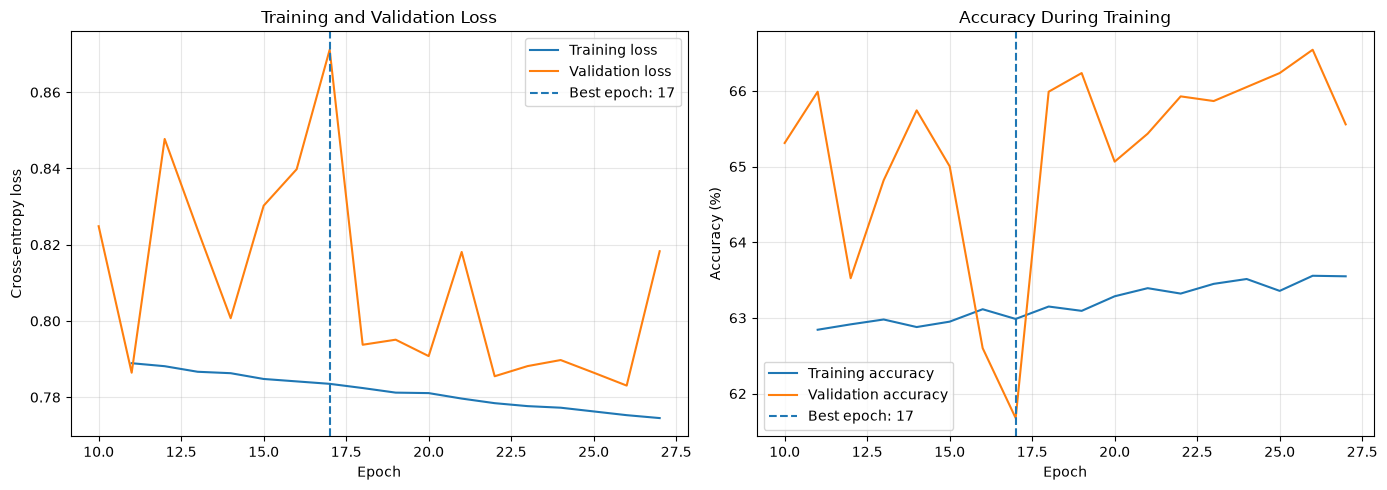

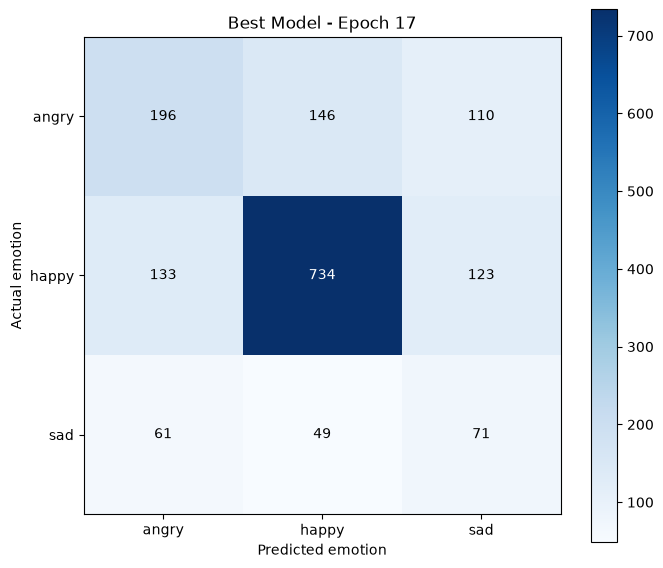

BEST MODEL - PER-CLASS RECALL
angry   : 43.36%
happy   : 74.14%
sad     : 39.23%

FINAL VALIDATION METRICS
Overall accuracy: 61.68%
Balanced accuracy: 52.24%
Validation loss:   0.8711


In [65]:
import matplotlib.pyplot as plt

epochs = history["epoch"]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

# Loss history

axes[0].plot(
    epochs,
    history["train_loss"],
    label="Training loss",
)

axes[0].plot(
    epochs,
    history["val_loss"],
    label="Validation loss",
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# accurate history

axes[1].plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    label="Training accuracy",
    )

axes[1].plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    label="Validation accuracy",
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}",
)

axes[1].set_title("Accuracy During Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# confusion matrix for best model

cm = best_results["confusion_matrix"]

fig, ax = plt.subplots(figsize=(7,6))

image = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_yticks(range(len(CLASS_NAMES)))

ax.set_xticklabels(CLASS_NAMES)
ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted emotion")
ax.set_ylabel("Actual emotion")
ax.set_title(f"Best Model - Epoch {best_epoch}")

for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):

        ax.text(
            j,
            i,
            str(cm[i,j]),
            ha="center",
            va="center",
            color=(
                "white"
                if cm[i,j] > cm.max() / 2
                else "black"
            ),
        )

fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

# final class recall
print("BEST MODEL - PER-CLASS RECALL")
print("=" * 45)

for class_name, recall in zip(
    CLASS_NAMES,
    best_results["recalls"],
):
    print(f"{class_name:<8}: {recall:.2%}")

print("\nFINAL VALIDATION METRICS")
print("=" * 45)

print(f"Overall accuracy: {best_results['accuracy']:.2%}")
print(f"Balanced accuracy: {best_results['balanced_accuracy']:.2%}")
print(f"Validation loss:   {best_results['loss']:.4f}")

### Check for data leakage between our augmented training images and validtion set

In [66]:

from pathlib import Path
from collections import Counter

import numpy as np
from PIL import Image
from scipy.fft import dctn
from tqdm.auto import tqdm

from capstone_data.image_loader import load_dataset


# --------------------------------------------------
# 1. Locate original images used for augmentation
# --------------------------------------------------

aug_dataset = load_dataset("aug_data_v1")

original_records = [
    item for item in aug_dataset
    if Path(item["path"]).name.startswith("original_")
]

print("Augmented dataset:", len(aug_dataset))
print("Original training images:", len(original_records))
print("Validation images:", len(X_val))

print(
    "Original training distribution:",
    Counter(item["class_name"] for item in original_records)
)


# --------------------------------------------------
# 2. Convert images to comparable 48x48 arrays
# --------------------------------------------------

def image_to_uint8(image):
    array = np.asarray(image).squeeze()

    if array.size != 48 * 48:
        raise ValueError(
            f"Expected 2304 pixels, got shape {array.shape}"
        )

    array = array.reshape(48, 48).astype(np.float32)

    if array.min() < 0 or array.max() > 255:
        raise ValueError(
            "Images appear to have been standardized. "
            "We need their original pixel values."
        )

    if array.max() <= 1.0:
        array *= 255.0

    return np.clip(
        np.rint(array), 0, 255
    ).astype(np.uint8)


# --------------------------------------------------
# 3. Compute perceptual hashes
# --------------------------------------------------

def phash(image):
    image = Image.fromarray(
        image_to_uint8(image)
    ).resize((32, 32), Image.Resampling.LANCZOS)

    pixels = np.asarray(image, dtype=np.float32)

    frequencies = dctn(
        pixels,
        type=2,
        norm="ortho"
    )[:8, :8].ravel()

    coefficients = frequencies[1:]
    bits = coefficients > np.median(coefficients)

    return int.from_bytes(
        np.packbits(bits).tobytes(),
        byteorder="big"
    )


original_paths = [
    Path(item["path"]) for item in original_records
]

original_hashes = []

for path in tqdm(original_paths, desc="Hashing training originals"):
    with Image.open(path) as image:
        original_hashes.append(
            phash(image.convert("L"))
        )

original_hashes = np.array(
    original_hashes,
    dtype=np.uint64
)

# Lookup table for counting differing bits
bit_counts = np.array(
    [int(i).bit_count() for i in range(256)],
    dtype=np.uint8
)


# --------------------------------------------------
# 4. Compare validation images to training originals
# --------------------------------------------------

confirmed_matches = []
possible_matches = []

for val_index, val_image in enumerate(
    tqdm(X_val, desc="Checking validation images")
):
    val_pixels = image_to_uint8(val_image)
    val_hash = np.uint64(phash(val_pixels))

    differences = np.bitwise_xor(
        original_hashes, val_hash
    )

    distances = bit_counts[
        differences.view(np.uint8).reshape(-1, 8)
    ].sum(axis=1)

    # Perceptual hash distance <= 6 is suspicious
    candidates = np.flatnonzero(distances <= 6)

    for train_index in candidates:
        path = original_paths[train_index]

        with Image.open(path) as image:
            train_pixels = image_to_uint8(
                image.convert("L")
            )

        mean_error = np.abs(
            val_pixels.astype(np.float32)
            - train_pixels.astype(np.float32)
        ).mean()

        match = {
            "validation_index": val_index,
            "training_path": str(path),
            "hash_distance": int(distances[train_index]),
            "mean_pixel_error": round(float(mean_error), 3),
        }

        if mean_error <= 5:
            confirmed_matches.append(match)
        else:
            possible_matches.append(match)


# --------------------------------------------------
# 5. Report findings
# --------------------------------------------------

print("\n" + "=" * 55)
print("DATA LEAKAGE AUDIT")
print("=" * 55)

print("Validation images:", len(X_val))

print(
    "Validation images with strong matches:",
    len(set(
        m["validation_index"]
        for m in confirmed_matches
    ))
)

print(
    "Strong matching pairs:",
    len(confirmed_matches)
)

print(
    "Additional perceptual-hash candidates:",
    len(possible_matches)
)

print("\nFirst 10 strong matches:")

for match in confirmed_matches[:10]:
    print(match)

if not confirmed_matches:
    print(
        "\nNo strong near-duplicate matches detected. "
        "This is encouraging, but does not prove "
        "that the dataset splits are independent."
    )
else:
    print(
        "\nWARNING: Strong near-duplicate matches found. "
        "Investigate these before trusting validation metrics."
    )


Augmented dataset: 14019
Original training images: 7681
Validation images: 1623
Original training distribution: Counter({'happy': 4673, 'angry': 2163, 'sad': 845})


Hashing training originals:   0%|          | 0/7681 [00:00<?, ?it/s]

Checking validation images:   0%|          | 0/1623 [00:00<?, ?it/s]


DATA LEAKAGE AUDIT
Validation images: 1623
Validation images with strong matches: 6
Strong matching pairs: 10
Additional perceptual-hash candidates: 72

First 10 strong matches:
{'validation_index': 93, 'training_path': 'C:\\Users\\mashe\\code\\class\\Capstone-DATA4381\\data\\augmented_data\\aug_data_v1\\angry\\original_001055.jpg', 'hash_distance': 0, 'mean_pixel_error': 4.685}
{'validation_index': 93, 'training_path': 'C:\\Users\\mashe\\code\\class\\Capstone-DATA4381\\data\\augmented_data\\aug_data_v1\\angry\\original_002021.jpg', 'hash_distance': 0, 'mean_pixel_error': 4.685}
{'validation_index': 128, 'training_path': 'C:\\Users\\mashe\\code\\class\\Capstone-DATA4381\\data\\augmented_data\\aug_data_v1\\angry\\original_000244.jpg', 'hash_distance': 2, 'mean_pixel_error': 3.069}
{'validation_index': 251, 'training_path': 'C:\\Users\\mashe\\code\\class\\Capstone-DATA4381\\data\\augmented_data\\aug_data_v1\\angry\\original_001533.jpg', 'hash_distance': 0, 'mean_pixel_error': 1.263}
{'v

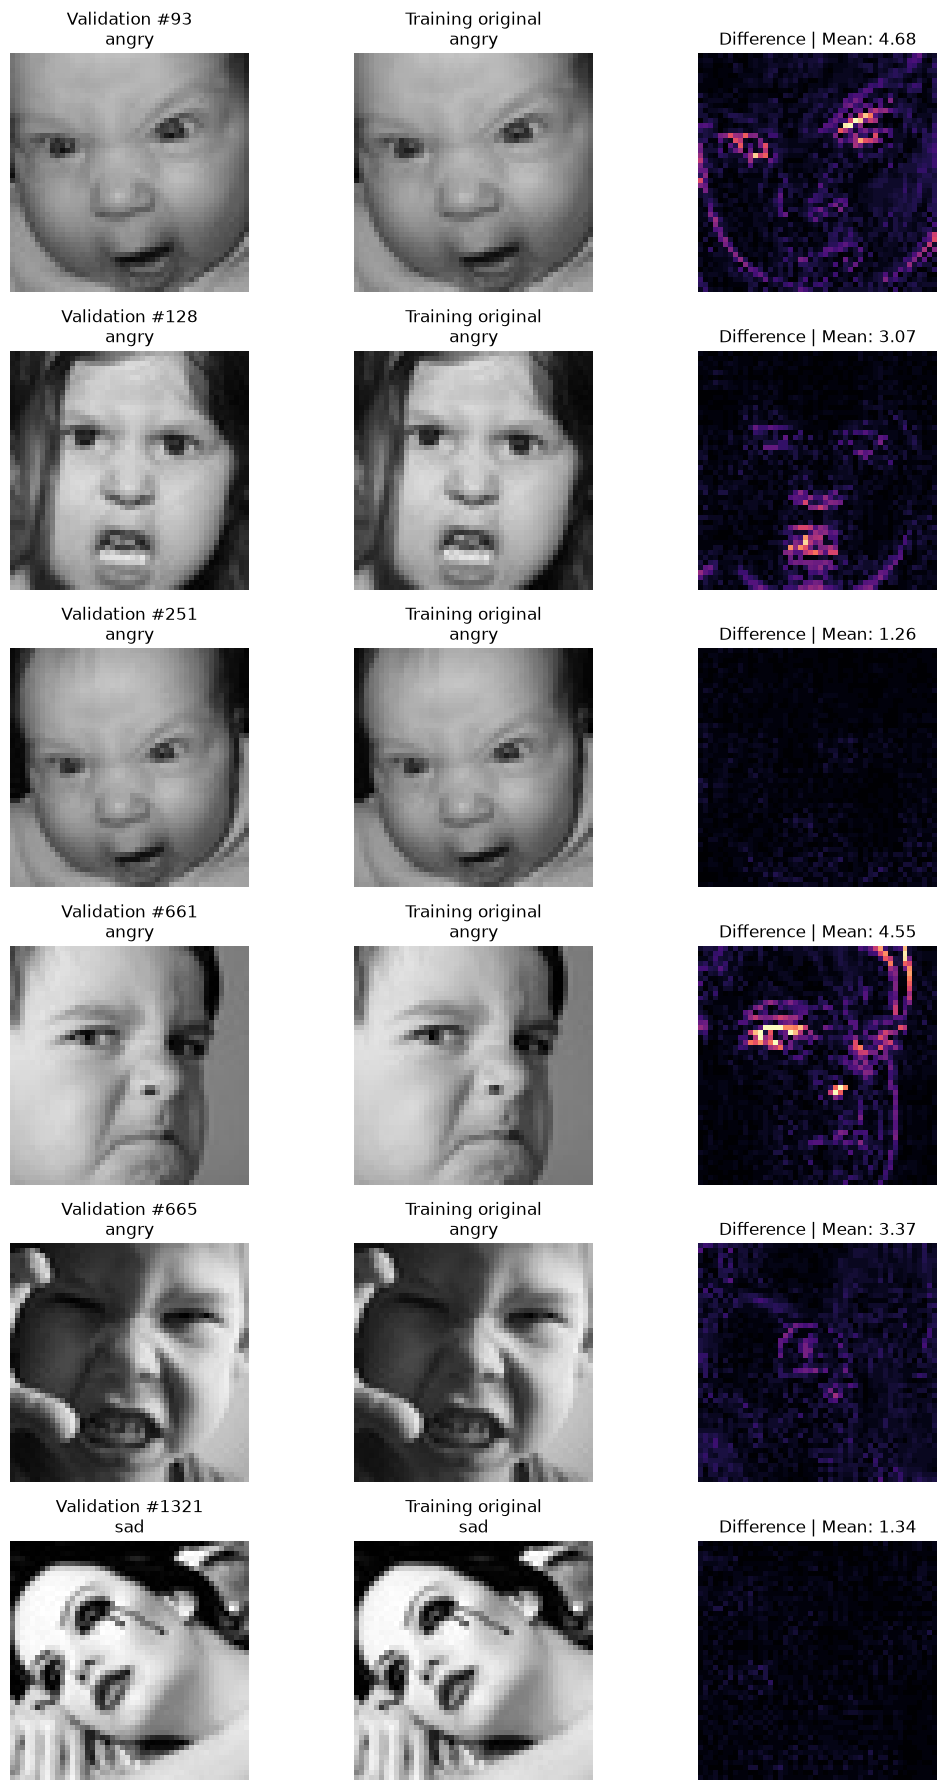

In [67]:

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

# Keep the closest training match for each validation image
best_matches = {}

for match in confirmed_matches:
    index = match["validation_index"]

    if (
        index not in best_matches
        or match["mean_pixel_error"]
        < best_matches[index]["mean_pixel_error"]
    ):
        best_matches[index] = match

matches = sorted(best_matches.values(),
                 key=lambda m: m["validation_index"])

fig, axes = plt.subplots(
    len(matches), 3,
    figsize=(11, 3 * len(matches)),
    squeeze=False
)

for row, match in enumerate(matches):
    index = match["validation_index"]

    validation_image = image_to_uint8(X_val[index])

    with Image.open(match["training_path"]) as img:
        training_image = np.asarray(
            img.convert("L"), dtype=np.uint8
        )

    difference = np.abs(
        validation_image.astype(np.int16)
        - training_image.astype(np.int16)
    )

    axes[row, 0].imshow(validation_image, cmap="gray",
                        vmin=0, vmax=255)
    axes[row, 1].imshow(training_image, cmap="gray",
                        vmin=0, vmax=255)
    axes[row, 2].imshow(difference, cmap="magma",
                        vmin=0, vmax=50)

    validation_class = CLASS_NAMES[int(y_val[index])]
    training_class = Path(match["training_path"]).parent.name

    axes[row, 0].set_title(
        f"Validation #{index}\n{validation_class}"
    )
    axes[row, 1].set_title(
        f"Training original\n{training_class}"
    )
    axes[row, 2].set_title(
        f"Difference | Mean: {match['mean_pixel_error']:.2f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [68]:

from pathlib import Path
import pandas as pd

from capstone_data.image_loader import (
    CLASS_NAMES,
    get_project_paths,
    list_datasets,
)

# --------------------------------------------------
# 1. Locate the existing datasets
# --------------------------------------------------

paths = get_project_paths()
project_root = paths["root"]

aug_v1_dir = list_datasets()["aug_data_v1"]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

audit_records = []


# --------------------------------------------------
# 2. Resolve image paths safely
# --------------------------------------------------

def resolve_image_path(value):
    path = Path(value)

    candidates = [
        path,
        project_root / path,
        paths["data"] / path,
    ]

    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()

    raise FileNotFoundError(
        f"Cannot locate image: {value}"
    )


# --------------------------------------------------
# 3. Collect original training images only
# --------------------------------------------------

for class_name in CLASS_NAMES:

    class_dir = aug_v1_dir / class_name

    originals = sorted(
        path
        for path in class_dir.rglob("original_*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    for path in originals:
        audit_records.append({
            "partition": "train",
            "class_name": class_name,
            "path": path.resolve(),
        })


# --------------------------------------------------
# 4. Add our cleaned holdout partitions
# --------------------------------------------------

def add_holdout_records(df, partition):

    possible_columns = (
        "path",
        "source_path",
        "image_path",
        "file_path",
        "original_path",
    )

    path_column = next(
        (
            column
            for column in possible_columns
            if column in df.columns
        ),
        None,
    )

    if path_column is None:
        raise ValueError(
            f"No image path column found in {partition}. "
            f"Available columns: {list(df.columns)}"
        )

    if "class_name" not in df.columns:
        raise ValueError(
            f"Missing class_name column in {partition}."
        )

    for _, row in df.iterrows():

        audit_records.append({
            "partition": partition,
            "class_name": row["class_name"],
            "path": resolve_image_path(
                row[path_column]
            ),
        })


add_holdout_records(val_clean_df, "validation")
add_holdout_records(test_clean_df, "test")


# --------------------------------------------------
# 5. Create our audit manifest
# --------------------------------------------------

audit_df = pd.DataFrame(audit_records)

print("DUPLICATE AUDIT MANIFEST")
print("=" * 50)

print(f"Total images: {len(audit_df):,}")

print("\nPartition and class distribution:")
print(
    pd.crosstab(
        audit_df["partition"],
        audit_df["class_name"],
        margins=True,
    )
)

print("\nUnique file paths:",
      audit_df["path"].nunique())

print("\nExact path overlap across partitions:")

path_partition_counts = (
    audit_df.groupby("path")["partition"].nunique()
)

print(
    (path_partition_counts > 1).sum()
)

print("\nManifest ready for image-content analysis.")


DUPLICATE AUDIT MANIFEST
Total images: 10,928

Partition and class distribution:
class_name  angry  happy   sad    All
partition                            
test          453    991   180   1624
train        2163   4673   845   7681
validation    452    990   181   1623
All          3068   6654  1206  10928

Unique file paths: 10928

Exact path overlap across partitions:
0

Manifest ready for image-content analysis.


In [69]:
%pip install ImageHash

   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ------------------------------- -------- 3.4/4.3 MB 18.0 MB/s eta 0:00:01
   ---------------------------------------- 4.3/4.3 MB 16.9 MB/s  0:00:00

   ---------------------------------------- 0/2 [PyWavelets]
   -------------------- ------------------- 1/2 [ImageHash]
   ---------------------------------------- 2/2 [ImageHash]

Note: you may need to restart the kernel to use updated packages.


In [70]:

import hashlib
import imagehash
import numpy as np

from PIL import Image
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Fingerprint a single image
# --------------------------------------------------

def fingerprint_image(path):

    with Image.open(path) as image:

        gray = image.convert("L")

        pixels = np.asarray(
            gray,
            dtype=np.uint8,
        )

        # Exact hash of decoded grayscale pixels
        exact_hash = hashlib.sha256(
            pixels.tobytes()
        ).hexdigest()

        # Perceptual hash for near-duplicate detection
        perceptual_hash = str(
            imagehash.phash(gray)
        )

    return exact_hash, perceptual_hash


# --------------------------------------------------
# 2. Fingerprint all images
# --------------------------------------------------

exact_hashes = []
perceptual_hashes = []

for path in tqdm(
    audit_df["path"],
    desc="Fingerprinting images",
):

    exact_hash, perceptual_hash = (
        fingerprint_image(path)
    )

    exact_hashes.append(exact_hash)
    perceptual_hashes.append(perceptual_hash)


audit_df["pixel_sha256"] = exact_hashes
audit_df["phash"] = perceptual_hashes


# --------------------------------------------------
# 3. Group exact duplicates
# --------------------------------------------------

hash_groups = (
    audit_df.groupby("pixel_sha256")
    .agg(
        image_count=("path", "size"),

        partitions=(
            "partition",
            lambda x: tuple(sorted(set(x))),
        ),

        classes=(
            "class_name",
            lambda x: tuple(sorted(set(x))),
        ),
    )
    .reset_index()
)

exact_duplicate_groups = hash_groups[
    hash_groups["image_count"] > 1
].copy()

cross_partition_groups = (
    exact_duplicate_groups[
        exact_duplicate_groups["partitions"].map(
            len
        ) > 1
    ].copy()
)

cross_class_groups = (
    exact_duplicate_groups[
        exact_duplicate_groups["classes"].map(
            len
        ) > 1
    ].copy()
)


# --------------------------------------------------
# 4. Report findings
# --------------------------------------------------

print("\nIMAGE FINGERPRINT AUDIT")
print("=" * 55)

print(
    f"Images fingerprinted: "
    f"{len(audit_df):,}"
)

print(
    f"Unique pixel hashes: "
    f"{audit_df['pixel_sha256'].nunique():,}"
)

print(
    f"Exact duplicate groups: "
    f"{len(exact_duplicate_groups):,}"
)

print(
    f"Cross-partition duplicate groups: "
    f"{len(cross_partition_groups):,}"
)

print(
    f"Cross-class duplicate groups: "
    f"{len(cross_class_groups):,}"
)


# --------------------------------------------------
# 5. Show examples of cross-partition duplicates
# --------------------------------------------------

print("\nCROSS-PARTITION EXACT DUPLICATES")
print("=" * 55)

if cross_partition_groups.empty:

    print("No exact pixel duplicates found.")

else:

    matching_hashes = set(
        cross_partition_groups["pixel_sha256"]
    )

    matches = audit_df[
        audit_df["pixel_sha256"].isin(
            matching_hashes
        )
    ]

    for hash_value, group in list(
        matches.groupby("pixel_sha256")
    )[:5]:

        print("\nDuplicate group:")

        for _, row in group.iterrows():

            print(
                f"  {row['partition']:12s} "
                f"{row['class_name']:8s} "
                f"{row['path']}"
            )

print("\nFingerprint audit complete.")


Fingerprinting images:   0%|          | 0/10928 [00:00<?, ?it/s]


IMAGE FINGERPRINT AUDIT
Images fingerprinted: 10,928
Unique pixel hashes: 10,887
Exact duplicate groups: 41
Cross-partition duplicate groups: 0
Cross-class duplicate groups: 0

CROSS-PARTITION EXACT DUPLICATES
No exact pixel duplicates found.

Fingerprint audit complete.


In [71]:

import numpy as np
import pandas as pd

from tqdm.auto import tqdm

# Work with a clean positional index.
df = audit_df.reset_index(drop=True).copy()

# Convert hexadecimal pHashes into 64-bit integers.
hashes = np.array(
    [int(value, 16) for value in df["phash"]],
    dtype=np.uint64,
)

# Number of set bits in every possible byte.
bit_counts = np.array(
    [i.bit_count() for i in range(256)],
    dtype=np.uint8,
)

partitions = df["partition"].to_numpy()


def compare_partitions(
    left_partition,
    right_partition,
    threshold=4,
    batch_size=64,
):
    """
    Find cross-partition pHash candidates.

    Hamming distance = number of differing bits.

    This function does not modify any images.
    """

    left_indices = np.flatnonzero(
        partitions == left_partition
    )

    right_indices = np.flatnonzero(
        partitions == right_partition
    )

    matches = []

    for start in tqdm(
        range(0, len(left_indices), batch_size),
        desc=f"{left_partition} vs {right_partition}",
    ):

        batch_indices = left_indices[
            start:start + batch_size
        ]

        # XOR identifies differing hash bits.
        differences = (
            hashes[batch_indices, None]
            ^ hashes[None, right_indices]
        )

        # Count the differing bits.
        bytes_view = differences.view(
            np.uint8
        ).reshape(
            len(batch_indices),
            len(right_indices),
            8,
        )

        distances = bit_counts[
            bytes_view
        ].sum(axis=2)

        row_positions, col_positions = np.where(
            distances <= threshold
        )

        for row, col in zip(
            row_positions,
            col_positions,
        ):

            matches.append({
                "left_index": int(
                    batch_indices[row]
                ),
                "right_index": int(
                    right_indices[col]
                ),
                "phash_distance": int(
                    distances[row, col]
                ),
            })

    return matches


# --------------------------------------------------
# Compare all three partition combinations.
# --------------------------------------------------

all_matches = []

for left, right in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:

    all_matches.extend(
        compare_partitions(left, right)
    )


# --------------------------------------------------
# Construct candidate report.
# --------------------------------------------------

near_duplicate_candidates = pd.DataFrame(
    all_matches,
    columns=[
        "left_index",
        "right_index",
        "phash_distance",
    ],
)

print("\nPERCEPTUAL HASH LEAKAGE AUDIT")
print("=" * 55)

if near_duplicate_candidates.empty:

    print("No cross-partition pHash candidates found.")

else:

    candidates = near_duplicate_candidates

    for side in ("left", "right"):

        indices = candidates[
            f"{side}_index"
        ].to_numpy()

        candidates[
            f"{side}_partition"
        ] = partitions[indices]

        candidates[
            f"{side}_class"
        ] = df["class_name"].iloc[
            indices
        ].to_numpy()

        candidates[
            f"{side}_path"
        ] = df["path"].iloc[
            indices
        ].astype(str).to_numpy()

    candidates = candidates.sort_values(
        "phash_distance"
    ).reset_index(drop=True)

    near_duplicate_candidates = candidates

    print(
        f"Candidate matching pairs: "
        f"{len(candidates):,}"
    )

    for left, right in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:

        subset = candidates[
            (candidates["left_partition"] == left)
            & (candidates["right_partition"] == right)
        ]

        print(
            f"{left} vs {right}: "
            f"{len(subset):,} candidate pairs"
        )

        print(
            f"  Unique {right} images matched: "
            f"{subset['right_index'].nunique():,}"
        )

    cross_class = candidates[
        candidates["left_class"]
        != candidates["right_class"]
    ]

    print(
        f"\nCross-class candidate pairs: "
        f"{len(cross_class):,}"
    )

    print("\nFirst 20 candidate pairs:")

    display(
        candidates[
            [
                "left_partition",
                "left_class",
                "right_partition",
                "right_class",
                "phash_distance",
                "left_path",
                "right_path",
            ]
        ].head(20)
    )


train vs validation:   0%|          | 0/121 [00:00<?, ?it/s]

train vs test:   0%|          | 0/121 [00:00<?, ?it/s]

validation vs test:   0%|          | 0/26 [00:00<?, ?it/s]


PERCEPTUAL HASH LEAKAGE AUDIT
Candidate matching pairs: 85
train vs validation: 41 candidate pairs
  Unique validation images matched: 30
train vs test: 34 candidate pairs
  Unique test images matched: 24
validation vs test: 10 candidate pairs
  Unique test images matched: 8

Cross-class candidate pairs: 2

First 20 candidate pairs:


,left_partition,left_class,right_partition,right_class,phash_distance,left_path,right_path
0,train,angry,validation,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
1,train,angry,validation,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
2,train,angry,validation,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
3,train,happy,validation,happy,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\happy_cl...
4,train,angry,validation,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
5,train,angry,validation,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
6,train,angry,test,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
7,train,sad,validation,sad,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\sad_clea...
8,train,angry,test,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
9,train,angry,test,angry,0,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...


Comparing candidate pixels:   0%|          | 0/85 [00:00<?, ?it/s]


PIXEL SIMILARITY AUDIT
Total candidate pairs: 85
Identical pixel pairs: 0
Pairs with mean pixel error <= 5: 22
Pairs with mean pixel error <= 10: 44

Strongest 20 candidates:


,left_partition,right_partition,left_class,right_class,phash_distance,mean_absolute_error,identical_pixels
0,train,validation,angry,angry,0,1.263455,False
1,train,validation,angry,angry,0,1.263455,False
2,validation,test,angry,angry,0,1.312500,False
3,train,validation,sad,sad,0,1.338108,False
4,validation,test,angry,angry,0,1.389757,False
5,train,test,angry,angry,0,1.676649,False
6,train,test,angry,angry,0,1.676649,False
7,train,test,angry,angry,2,1.717448,False
8,train,test,angry,angry,2,1.737847,False
9,train,test,angry,angry,0,1.931424,False


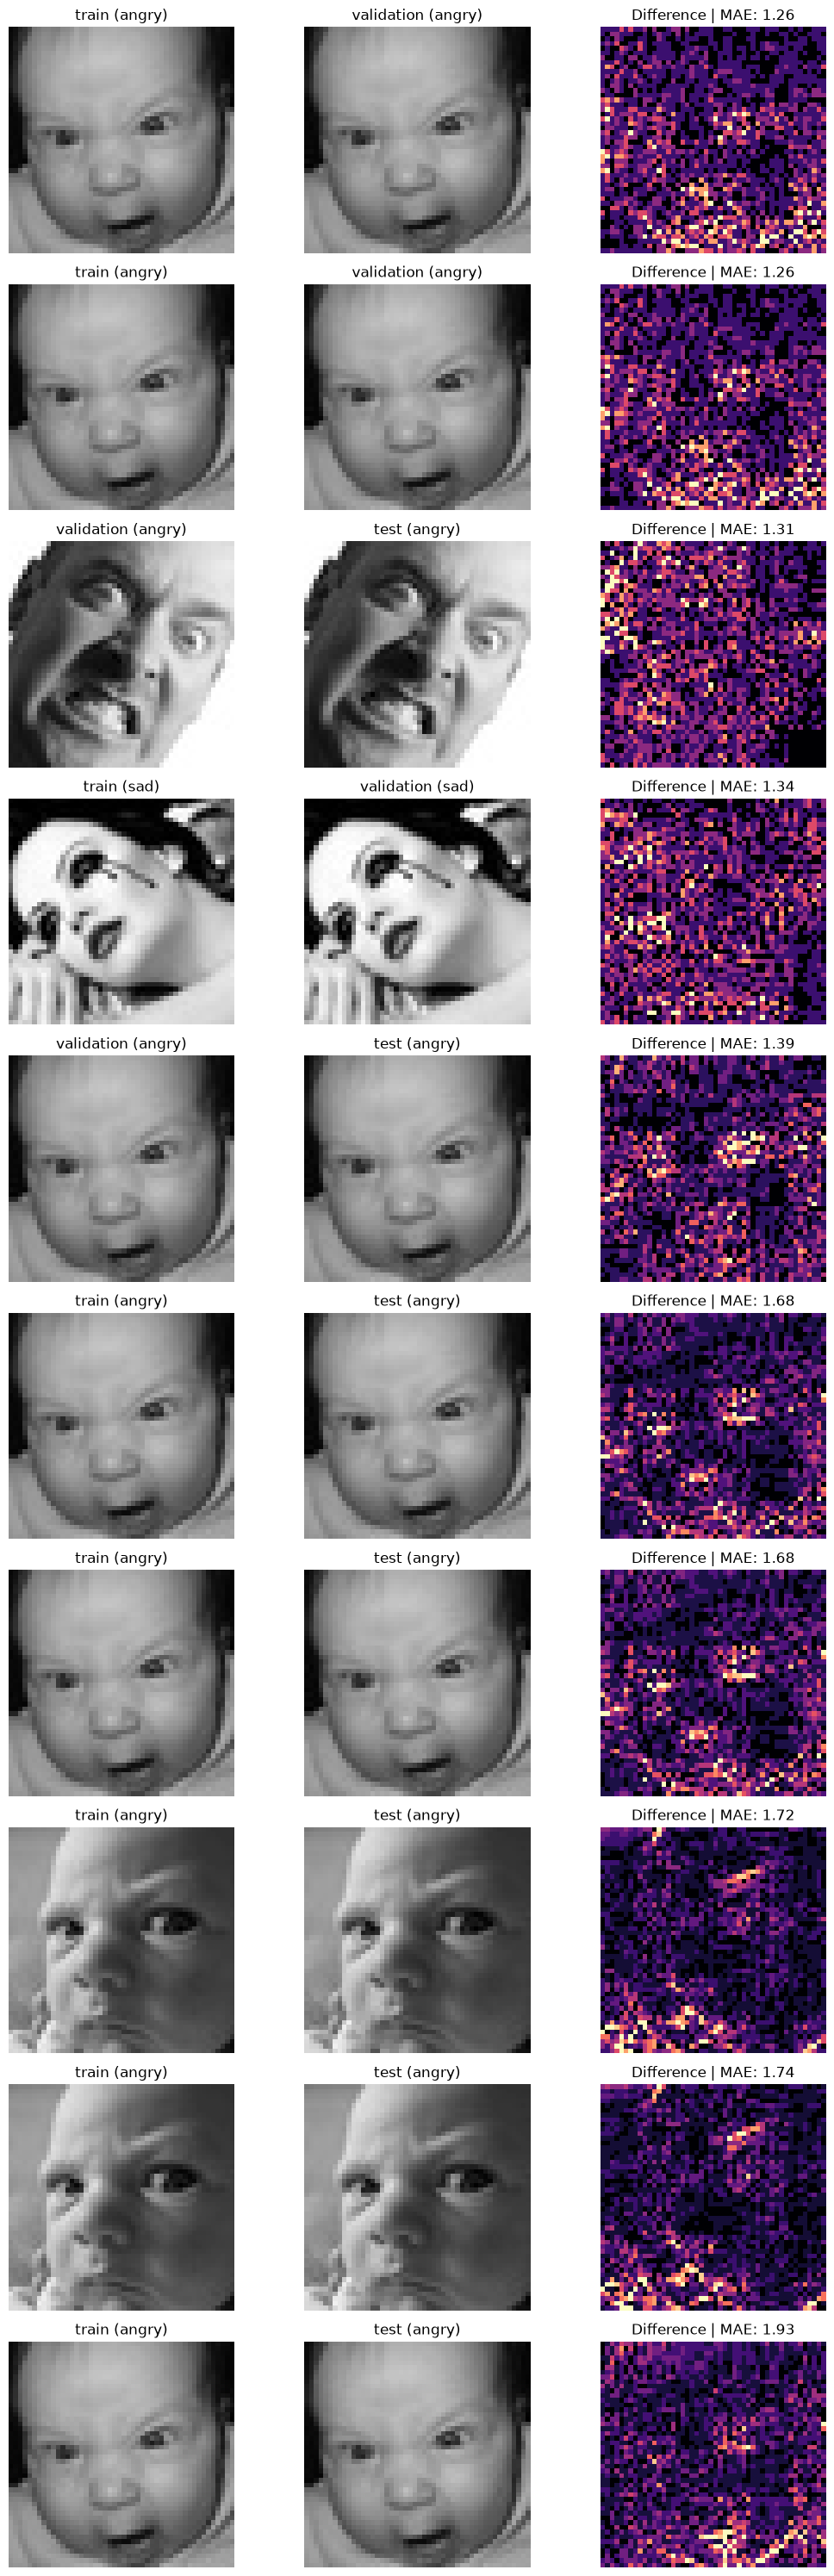

In [72]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm


def read_grayscale(path):
    """
    Load an image without resizing or modifying its pixels.
    """
    with Image.open(Path(path)) as image:
        return np.asarray(
            image.convert("L"),
            dtype=np.int16,
        )


def compare_image_pixels(left_path, right_path):
    """
    Compare two images using their actual pixel values.

    Returns:
        mean_absolute_error:
            Average absolute difference in pixel intensity.

        max_absolute_error:
            Largest individual pixel difference.

        identical_pixels:
            Whether all pixel values are identical.
    """

    left = read_grayscale(left_path)
    right = read_grayscale(right_path)

    if left.shape != right.shape:
        return {
            "mean_absolute_error": np.nan,
            "max_absolute_error": np.nan,
            "identical_pixels": False,
            "same_dimensions": False,
        }

    difference = np.abs(left - right)

    return {
        "mean_absolute_error": float(
            difference.mean()
        ),
        "max_absolute_error": int(
            difference.max()
        ),
        "identical_pixels": bool(
            np.array_equal(left, right)
        ),
        "same_dimensions": True,
    }


# --------------------------------------------------
# Score every pHash candidate.
# --------------------------------------------------

verified_candidates = near_duplicate_candidates.copy()

results = []

for row in tqdm(
    verified_candidates.itertuples(index=False),
    total=len(verified_candidates),
    desc="Comparing candidate pixels",
):

    results.append(
        compare_image_pixels(
            row.left_path,
            row.right_path,
        )
    )


metrics_df = pd.DataFrame(results)

verified_candidates = pd.concat(
    [
        verified_candidates.reset_index(drop=True),
        metrics_df,
    ],
    axis=1,
)

verified_candidates = verified_candidates.sort_values(
    [
        "mean_absolute_error",
        "phash_distance",
    ]
).reset_index(drop=True)


# --------------------------------------------------
# Summarize findings.
# --------------------------------------------------

print("\nPIXEL SIMILARITY AUDIT")
print("=" * 55)

print(
    f"Total candidate pairs: "
    f"{len(verified_candidates):,}"
)

print(
    f"Identical pixel pairs: "
    f"{verified_candidates['identical_pixels'].sum():,}"
)

print(
    f"Pairs with mean pixel error <= 5: "
    f"{(verified_candidates['mean_absolute_error'] <= 5).sum():,}"
)

print(
    f"Pairs with mean pixel error <= 10: "
    f"{(verified_candidates['mean_absolute_error'] <= 10).sum():,}"
)

print("\nStrongest 20 candidates:")

display(
    verified_candidates[
        [
            "left_partition",
            "right_partition",
            "left_class",
            "right_class",
            "phash_distance",
            "mean_absolute_error",
            "identical_pixels",
        ]
    ].head(20)
)


# --------------------------------------------------
# Visually inspect the strongest matches.
# --------------------------------------------------

num_examples = min(
    10,
    len(verified_candidates),
)

if num_examples > 0:

    fig, axes = plt.subplots(
        num_examples,
        3,
        figsize=(11, 3 * num_examples),
        squeeze=False,
    )

    for i in range(num_examples):

        row = verified_candidates.iloc[i]

        left = read_grayscale(
            row["left_path"]
        )

        right = read_grayscale(
            row["right_path"]
        )

        difference = np.abs(left - right)

        axes[i, 0].imshow(
            left,
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        axes[i, 1].imshow(
            right,
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        axes[i, 2].imshow(
            difference,
            cmap="magma",
            vmin=0,
            vmax=max(
                1,
                np.percentile(difference, 99),
            ),
        )

        axes[i, 0].set_title(
            f"{row['left_partition']} "
            f"({row['left_class']})"
        )

        axes[i, 1].set_title(
            f"{row['right_partition']} "
            f"({row['right_class']})"
        )

        axes[i, 2].set_title(
            f"Difference | "
            f"MAE: {row['mean_absolute_error']:.2f}"
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


In [73]:

# Strong near-duplicate candidates.
# These thresholds are for triage, not automatic deletion.

strong_matches = verified_candidates[
    (verified_candidates["phash_distance"] <= 2)
    & (verified_candidates["mean_absolute_error"] <= 5)
    & (verified_candidates["same_dimensions"])
    & (
        verified_candidates["left_class"]
        == verified_candidates["right_class"]
    )
].copy()

print("STRONG NEAR-DUPLICATE AUDIT")
print("=" * 50)

print(f"Matching pairs: {len(strong_matches):,}")

for partition in ["train", "validation", "test"]:

    left_indices = strong_matches.loc[
        strong_matches["left_partition"] == partition,
        "left_index",
    ]

    right_indices = strong_matches.loc[
        strong_matches["right_partition"] == partition,
        "right_index",
    ]

    affected = set(left_indices) | set(right_indices)

    print(
        f"{partition:<12}: "
        f"{len(affected):,} affected images"
    )

print("\nMatches by partition pair:")

print(
    strong_matches.groupby(
        ["left_partition", "right_partition"]
    ).size()
)

print("\nStrongest matching pairs:")

display(
    strong_matches[
        [
            "left_partition",
            "right_partition",
            "left_class",
            "phash_distance",
            "mean_absolute_error",
            "left_path",
            "right_path",
        ]
    ].sort_values(
        "mean_absolute_error"
    ).head(30)
)


STRONG NEAR-DUPLICATE AUDIT
Matching pairs: 22
train       : 12 affected images
validation  : 8 affected images
test        : 5 affected images

Matches by partition pair:
left_partition  right_partition
train           test                8
                validation         10
validation      test                4
dtype: int64

Strongest matching pairs:


,left_partition,right_partition,left_class,phash_distance,mean_absolute_error,left_path,right_path
0,train,validation,angry,0,1.263455,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
1,train,validation,angry,0,1.263455,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
2,validation,test,angry,0,1.312500,C:\Users\mashe\Downloads\cleaned_data\angry_cl...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
3,train,validation,sad,0,1.338108,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\sad_clea...
4,validation,test,angry,0,1.389757,C:\Users\mashe\Downloads\cleaned_data\angry_cl...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
5,train,test,angry,0,1.676649,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
6,train,test,angry,0,1.676649,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
7,train,test,angry,2,1.717448,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
8,train,test,angry,2,1.737847,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
9,train,test,angry,0,1.931424,C:\Users\mashe\code\class\Capstone-DATA4381\da...,C:\Users\mashe\Downloads\cleaned_data\angry_cl...
